# DragonThree — Data collection, cleaning, provenance, and analysis

**CIS 5190 · Option B · November 3, 2026**

This notebook documents the report's data and recomputes descriptive statistics from explicitly
approved training/development snapshots. Collection and expensive reconstruction are **off by default**.
It does not train a classifier. Historical experiment evidence ends on October 29, 2026.

**Reading map:** submission contract → sources → data ledger → text conversion → cleanup →
event splits → record-level provenance → annotation review → distribution analysis → collection code.

Primary evidence: course requirements (local reference),
handoff (local reference), source index (local reference),
[package manifest](data/manifests/approved_inputs.json). Historical Python source is preserved as text under
source_archive; it is never imported or executed by these notebooks.

> Team review: inspect saved summaries first. Approved local data and checkpoints must be obtained separately. Archived collectors are historical references.


## Team setup and input check

The [reproduction guide](data/TEAM_REPRODUCTION.md) lists the local inputs for each branch. Run this check first. Run All skips a branch until its expected files are present. Saved evidence remains available for review.


In [ ]:
from pathlib import Path

TEAM_REPLAY_ROOT = Path.cwd().resolve()
if not (TEAM_REPLAY_ROOT / "data/manifests/approved_inputs.json").is_file():
    raise RuntimeError("Use the project root as the Notebook working directory.")

TEAM_REPLAY_INPUTS = {'course-cleaning-demo': ['data/before_cleaning/course_original_train.csv', 'data/before_cleaning/course_dev.csv'], 'self-collected-replay': ['data/before_cleaning/self_collected/replay_inputs/eligible_pairs.jsonl', 'data/before_cleaning/self_collected/replay_inputs/pair_review_decisions.json', 'data/before_cleaning/self_collected/replay_inputs/new_metadata.jsonl', 'data/team_review/new_train.csv', 'data/team_review/paired_train.csv', 'data/team_review/paired_dev.csv'], 'new-training-rebuild': ['data/before_cleaning/self_collected/new_training_rebuild/to_verify.jsonl', 'data/before_cleaning/self_collected/new_training_rebuild/special_to_verify.jsonl', 'data/before_cleaning/self_collected/new_training_rebuild/extra_to_verify.jsonl', 'data/before_cleaning/self_collected/new_training_rebuild/verification_cache.jsonl', 'data/before_cleaning/self_collected/new_training_rebuild/topic_review_overrides.json', 'data/before_cleaning/self_collected/new_training_rebuild/pair_review_decisions.json', 'data/before_cleaning/self_collected/new_training_rebuild/excluded_records.jsonl', 'data/before_cleaning/self_collected/new_training_rebuild/automatic_group_edges.jsonl', 'data/before_cleaning/self_collected/new_training_rebuild/dedup_reference_urls.csv', 'data/before_cleaning/self_collected/replay_inputs/new_metadata.jsonl', 'data/team_review/new_train.csv']}

TEAM_REPLAY_READY = {
    branch: all((TEAM_REPLAY_ROOT / rel).is_file() for rel in inputs)
    for branch, inputs in TEAM_REPLAY_INPUTS.items()
}
for branch, inputs in TEAM_REPLAY_INPUTS.items():
    if TEAM_REPLAY_READY[branch]:
        print(f"{branch}: inputs ready")
    else:
        missing = [rel for rel in inputs if not (TEAM_REPLAY_ROOT / rel).is_file()]
        print(f"{branch}: skipped; missing {len(missing)} local input(s)")
        for rel in missing:
            print(f"  {rel}")


## Start here — rebuild the course cleaning outputs

1. Read the original course training URLs in [data/before_cleaning/](data/before_cleaning/README.md). The separate course development file is a reference for the historical near-duplicate check.
2. Extract the final URL slug, drop unusable or repeated model text, then apply the historical near-duplicate rules using that reference.
3. Write three new CSVs under data/generated/course_cleaning/: cleaned training, excluded rows with reasons, and removal counts. No collection or fitting is involved. Existing identical outputs are reused.

Run the following four code cells in order, or use Run All for the share demonstration. The historical replay of the other data panels below remains disabled by default. The development set is reused in cleaning, so this pipeline does not establish an independently untouched development evaluation.


### 1. Load the before-cleaning inputs

The raw training file has 3,849 URLs. The separate 951-row reference is the course development split.

In [ ]:
if TEAM_REPLAY_READY['course-cleaning-demo']:
    from pathlib import Path
    import csv
    import os
    import sys
    
    CLEANING_ROOT = Path.cwd().resolve()
    if not (CLEANING_ROOT / "data/before_cleaning").is_dir():
        raise RuntimeError("Open this notebook with the Desktop project folder as its working directory.")
    source_dir = CLEANING_ROOT / "src"
    if str(source_dir) not in sys.path:
        sys.path.insert(0, str(source_dir))
    
    import pandas as pd
    from dragonthree.project_io import url_to_text, label_from_url, text_group
    
    raw_dir = CLEANING_ROOT / "data/before_cleaning"
    
    def read_course_urls(filename, expected_rows):
        path = raw_dir / filename
        if path.resolve(strict=True) != path:
            raise PermissionError("The input must be a regular project file at its documented path.")
        with path.open(encoding="utf-8-sig", newline="") as handle:
            reader = csv.DictReader(handle)
            if reader.fieldnames != ["url"]:
                raise ValueError(f"Unexpected columns in {filename}")
            rows = list(reader)
        if len(rows) != expected_rows:
            raise ValueError(f"Unexpected record count in {filename}")
        return pd.DataFrame(rows)
    
    raw_training = read_course_urls("course_original_train.csv", 3849)
    course_development = read_course_urls("course_dev.csv", 951)
    print(f"Loaded {len(raw_training):,} raw training URLs and {len(course_development):,} course development reference URLs.")


### 2. Define the historical cleaning rules

The rules handle conflicting labels, duplicate or empty text, and near duplicates of the course development references.

In [ ]:
if TEAM_REPLAY_READY['course-cleaning-demo']:
    def reconstruct_course_cleanup(raw, development_texts, include_near_duplicates=False):
        """Course-only historical rules; no mixed metadata or sealed input."""
        from collections import defaultdict
        known, seen, keep, removed = defaultdict(set), set(), [], []
        for url in raw["url"]:
            known[text_group(url_to_text(url))].add(label_from_url(url))
        for url in raw["url"]:
            text = url_to_text(url)
            group = text_group(text)
            reason = ("identical_text_conflicting_labels" if len(known[group]) > 1 else
                      "duplicate_model_text" if group in seen else
                      "empty_model_text" if not group else "")
            if reason:
                removed.append({"url": url, "text": text, "reason": reason})
            else:
                seen.add(group)
                keep.append({"url": url, "text": text})
        if include_near_duplicates:
            from sklearn.feature_extraction.text import TfidfVectorizer
            from sklearn.neighbors import NearestNeighbors
            vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), strip_accents="unicode")
            matrix = vec.fit_transform(list(development_texts) + [r["text"] for r in keep])
            ndev = len(development_texts)
            distance, index = NearestNeighbors(n_neighbors=3, metric="cosine", algorithm="brute",
                n_jobs=1).fit(matrix[:ndev]).kneighbors(matrix[ndev:])
            filtered = []
            for row, ds, js in zip(keep, distance, index):
                a = set(text_group(row["text"]).split())
                matches = False
                for d, j in zip(ds, js):
                    b = set(text_group(development_texts[int(j)]).split())
                    shared = len(a & b)
                    matches |= 1 - d >= .90 or (
                        shared >= 5 and (shared / max(1, len(a | b)) >= .80 or
                                         shared / max(1, min(len(a), len(b))) >= .93))
                if matches:
                    removed.append({**row, "reason": "near_duplicate_of_course_dev"})
                else:
                    filtered.append(row)
            keep = filtered
        return pd.DataFrame(keep), pd.DataFrame(removed)


### 3. Apply cleaning and inspect the counts

Only training rows can enter the cleaned training output. The development rows are used for comparison.

In [ ]:
if TEAM_REPLAY_READY['course-cleaning-demo']:
    development_texts = course_development["url"].map(url_to_text).tolist()
    cleaned, exclusions = reconstruct_course_cleanup(raw_training, development_texts, include_near_duplicates=True)
    
    assert len(cleaned) + len(exclusions) == len(raw_training)
    assert not cleaned["text"].map(text_group).duplicated().any()
    assert cleaned["text"].map(text_group).ne("").all()
    assert set(cleaned["url"]).isdisjoint(exclusions["url"])
    
    cleaned = cleaned.assign(label=cleaned["url"].map(label_from_url))
    assert cleaned["label"].isin(["FoxNews", "NBC"]).all()
    cleaned = cleaned[["url", "text", "label"]]
    exclusions = exclusions[["url", "text", "reason"]]
    summary = exclusions.groupby("reason").size().rename("rows").reset_index()
    print(f"Training URLs: {len(raw_training):,}; kept: {len(cleaned):,}; excluded: {len(exclusions):,}")
    display(summary)


### 4. Generate the three output CSVs

Open data/generated/course_cleaning/ in the file explorer after running this cell. The exclusion report explains why each removed row was dropped.

In [ ]:
if TEAM_REPLAY_READY['course-cleaning-demo']:
    output_dir = CLEANING_ROOT / "data/generated/course_cleaning"
    if output_dir.resolve() != output_dir:
        raise PermissionError("Generated output must stay at its documented project path.")
    output_dir.mkdir(parents=True, exist_ok=True)
    outputs = {
        "course_clean.csv": cleaned,
        "course_exclusions.csv": exclusions,
        "cleaning_summary.csv": summary,
    }
    encoded = {name: table.to_csv(index=False, lineterminator="\n").encode("utf-8")
               for name, table in outputs.items()}
    for name, content in encoded.items():
        path = output_dir / name
        if path.is_symlink() or (path.exists() and path.read_bytes() != content):
            raise FileExistsError(f"Move the existing generated file before replacing it: {path}")
    for name, content in encoded.items():
        path = output_dir / name
        if not path.exists():
            with path.open("xb") as handle:
                handle.write(content)
    print("Generated CSVs:")
    for name in outputs:
        print((output_dir / name).relative_to(CLEANING_ROOT))


## Offline replay — self-collected training and development tables

See the [local replay inputs](data/before_cleaning/self_collected/replay_inputs/README.md) and the [saved team-review tables](data/team_review/README.md). These two branches start at different points in the historical workflow.

- **Event-paired branch:** 879 eligible event candidates plus the saved review decisions. Reapply the final story-family grouping, selection and deterministic topic-stratified split, then keep the agreed review fields.
- **New-training branch:** the already verified and selected 2,000-row snapshot. Keep the agreed review fields in original order. Earlier URL discovery, verification and selection are documented above the input files.

The notebook compares all three generated CSVs with the saved review copies before writing to data/generated/self_collected_replay/. This replay does not collect web pages, generate embeddings, or fit models.


### 1. Load eligible event pairs and their saved decisions

Check decision coverage and keep the historical input order.


In [ ]:
if TEAM_REPLAY_READY['self-collected-replay']:
    from collections import Counter, defaultdict
    import csv
    import io
    import json
    from pathlib import Path
    import re
    import numpy as np
    
    REPLAY_ROOT = Path.cwd().resolve()
    REPLAY_INPUTS = REPLAY_ROOT / "data/before_cleaning/self_collected/replay_inputs"
    REPLAY_OUTPUTS = REPLAY_ROOT / "data/generated/self_collected_replay"
    REPLAY_REFERENCE = REPLAY_ROOT / "data/team_review"
    
    def checked_replay_file(directory, filename):
        path = directory / filename
        if path.resolve(strict=True) != path or not path.is_file():
            raise PermissionError("Replay input must be a file at the documented path.")
        return path
    
    def replay_jsonl(name):
        path = checked_replay_file(REPLAY_INPUTS, name)
        with path.open(encoding="utf-8-sig") as handle:
            return [json.loads(line) for line in handle if line.strip()]
    
    def norm(text):
        return " ".join(re.findall("[a-z0-9]+", text.lower()))
    
    eligible_pairs = replay_jsonl("eligible_pairs.jsonl")
    review_decisions = json.loads(
        checked_replay_file(REPLAY_INPUTS, "pair_review_decisions.json").read_text(encoding="utf-8")
    )
    assert len(eligible_pairs) == 879
    eligible_ids = {row["proposal_id"] for row in eligible_pairs}
    accepted_ids = set(review_decisions["accepted"])
    rejected_ids = set(review_decisions["rejected"])
    assert len(eligible_ids) == len(eligible_pairs)
    assert not accepted_ids & rejected_ids and eligible_ids <= accepted_ids | rejected_ids
    print(f"{len(eligible_pairs):,} eligible pairs with a recorded decision")


### 2. Replay event selection and the train/development split

Apply the original finalization rules to the saved candidates. The earlier semantic proposal and verification steps are outside this replay.


In [ ]:
if TEAM_REPLAY_READY['self-collected-replay']:
    def replay_event_pairs(pairs, review):
        accepted=set(review['accepted']);rejected=set(review['rejected']);assert not accepted&rejected
        candidates=[r for r in pairs if r['proposal_id'] in accepted]
        accepted_eligible_count=len(candidates)
        # Title review also revealed continuing reports that narrow lexical grouping missed.
        # Collapse each such story family before splitting; this is deliberately conservative.
        families=[('trump_butler',r'trump.*(?:assassination|shooter|shooting)|(?:assassination|shooter|shooting).*trump'),
                  ('la_wildfires',r'california.*(?:wildfire|fire)|(?:wildfire|fire).*california|los angeles.*(?:wildfire|fire)'),
                  ('jordan_chiles_medal',r'jordan chiles.*(?:bronze|medal)'),
                  ('billy_joel_diagnosis',r'billy joel.*(?:brain|disorder|diagnosis)'),
                  ('smokey_robinson_case',r'smokey robinson.*(?:assault|lawsuit|accus)'),
                  ('harvard_international_students',r'harvard.*(?:visa|international student|enroll)'),
                  ('barstool_antisemitism',r'barstool.*(?:antisemit|incident)|antisemit.*barstool'),
                  ('mccullers_threats',r'mccullers.*(?:threat|security)'),
                  ('biles_skinner',r'mykayla skinner|simone biles.*(?:blocked|team nickname)'),
                  ('iran_campaign_hack',r'iran.*hack|hack.*iran'),
                  ('iran_israel_exchange',r'iran.*israel|israel.*iran'),
                  ('trump_ny_trial',r'trump.*(?:hush money|jury|gag order|criminal trial)|hush money.*trump'),
                  ('baltimore_bridge',r'baltimore.*bridge|bridge.*baltimore|francis scott key bridge'),
                  ('rashee_rice_crash',r'rashee rice.*(?:crash|wreck)'),
                  ('weinstein_appeal',r'weinstein.*(?:overturn|conviction)'),
                  ('india_pakistan_ceasefire',r'india.*pakistan.*(?:ceasefire|cease-fire)|ceasefire.*india.*pakistan')]
        merged=defaultdict(list)
        for r in candidates:
         r['topic']=review.get('topic_overrides',{}).get(r['proposal_id'],r['topic'])
         text=norm(r['fox']['headline']+' '+r['nbc']['headline']);family=next((name for name,pat in families if re.search(pat,text)),None)
         g='family_'+family+'_'+r['date'][:7] if family else r['event_group'];r['event_group']=g;merged[g].append(r)
        candidates=[max(rr,key=lambda r:r['verified_similarity']+(.06 if r['fox_words']<=8 else .025 if r['fox_words']<=10 else 0)) for rr in merged.values()]
        chosen=[];tc=Counter();ac=Counter();wire=Counter();used_text=set()
        # Broad topics balanced by source automatically because each event contributes one of each.
        # First reserve space in smaller topics; then fill by quality / short-Fox priority.
        ordered=sorted(candidates,key=lambda r:(sum(x['topic']==r['topic'] for x in candidates)>60,-(r['verified_similarity']+(.06 if r['fox_words']<=8 else .025 if r['fox_words']<=10 else 0))))
        for r in ordered:
         texts={norm(r[s]['model_text']) for s in ('fox','nbc')}
         if texts&used_text:continue
         if tc[r['topic']]>=125:continue
         if any(ac[(s,name)]>=35 for s in ('fox','nbc') for name in r[s]['authors'] if not re.search('associated press|reuters|afp',name,re.I)):continue
         if any(r[s]['wire_byline'] and wire[s]>=60 for s in ('fox','nbc')):continue
         chosen.append(r);tc[r['topic']]+=1;used_text|=texts
         for s in ('fox','nbc'):
          wire[s]+=r[s]['wire_byline']
          for name in r[s]['authors']:ac[s,name]+=1
         if len(chosen)==500:break
        if len(chosen)<480:raise RuntimeError(f'Only {len(chosen)} reviewed eligible diverse events; collect/review more rather than silently declare 500.')
        # Allocate confirmation groups within topic, deterministic and without model outcomes.
        dev=set();rng=np.random.default_rng(5190)
        for topicname in sorted(tc):
         rr=[r for r in chosen if r['topic']==topicname];count=max(1,round(.2*len(rr)))
         dev.update(rr[i]['event_group'] for i in rng.permutation(len(rr))[:count])
        records=[]
        for r in chosen:
         split='paired_confirmation' if r['event_group'] in dev else 'paired_train'
         for s in ('fox','nbc'):
          v=r[s];records.append({'event_group':r['event_group'],'proposal_id':r['proposal_id'],'split':split,'publisher':v['publisher'],'url':v['canonical_url'],'original_url':v['url'],'text':v['model_text'],'headline':v['headline'],'published_at':v['published_at'],'topic':r['topic'],'authors':'|'.join(v['authors']),'wire_byline':v['wire_byline'],'words':v['words'],'characters':v['characters'],'source_directory':v['directory_url'],'source_response_sha256':v['response_sha256'],'verified_similarity':r['verified_similarity'],'reviewer':'assistant','review_scope':'Both original-site metadata and paired headline event match; not independent human annotation.'})
        return records


### 3. Load the selected new-training snapshot, check all rows and export

Use the saved 2,000-row snapshot as the new-training starting point. Verify that the three outputs match the team-review copies before writing new files.


In [ ]:
if TEAM_REPLAY_READY['self-collected-replay']:
    pair_fields = ["event_group", "publisher", "split", "url", "text"]
    new_fields = ["record_id", "source_url", "publisher_label", "model_text",
                  "group_id", "published_month", "batch_id"]
    paired_rows = replay_event_pairs(eligible_pairs, review_decisions)
    paired_train_rows = [row for row in paired_rows if row["split"] == "paired_train"]
    paired_dev_rows = [row for row in paired_rows if row["split"] == "paired_confirmation"]
    assert len(paired_train_rows) == 800 and len(paired_dev_rows) == 200
    assert {r["event_group"] for r in paired_train_rows}.isdisjoint(
        {r["event_group"] for r in paired_dev_rows})
    assert all(sorted(v) == ["FoxNews", "NBC"] for v in (
        [row["publisher"] for row in paired_rows if row["event_group"] == group]
        for group in {row["event_group"] for row in paired_rows}
    ))
    
    new_train_rows = replay_jsonl("new_metadata.jsonl")
    assert len(new_train_rows) == 2000
    assert len({r["record_id"] for r in new_train_rows}) == 2000
    
    def review_csv(rows, fields):
        buffer = io.StringIO(newline="")
        writer = csv.DictWriter(buffer, fieldnames=fields)
        writer.writeheader()
        writer.writerows({key: row[key] for key in fields} for row in rows)
        return buffer.getvalue().encode("utf-8")
    
    candidate_csv = {
        "paired_train.csv": review_csv(paired_train_rows, pair_fields),
        "paired_dev.csv": review_csv(paired_dev_rows, pair_fields),
        "new_train.csv": review_csv(new_train_rows, new_fields),
    }
    for name, content in candidate_csv.items():
        reference = checked_replay_file(REPLAY_REFERENCE, name)
        if content != reference.read_bytes():
            raise ValueError(f"Replay differs from the saved team-review table: {name}")
    
    if REPLAY_OUTPUTS.resolve() != REPLAY_OUTPUTS:
        raise PermissionError("Replay output must stay in the project directory.")
    REPLAY_OUTPUTS.mkdir(parents=True, exist_ok=True)
    for name, content in candidate_csv.items():
        path = REPLAY_OUTPUTS / name
        if path.is_symlink() or (path.exists() and path.read_bytes() != content):
            raise FileExistsError(f"Move the existing output before replacing it: {path}")
    for name, content in candidate_csv.items():
        path = REPLAY_OUTPUTS / name
        if not path.exists():
            with path.open("xb") as handle:
                handle.write(content)
    
    for name, rows in [("new_train.csv", new_train_rows), ("paired_train.csv", paired_train_rows),
                       ("paired_dev.csv", paired_dev_rows)]:
        print(f"{name}: {len(rows):,} rows, exact match to team_review")
    print(f"Generated copies: {REPLAY_OUTPUTS.relative_to(REPLAY_ROOT)}")


## Offline rebuild — supplemental new training from verified candidates

This starts earlier than the selected-snapshot export. See the [local input guide](data/before_cleaning/self_collected/new_training_rebuild/README.md). The historical waitlists and saved cache fix the verification inputs. Discovery and formation of the verification queue are upstream of this replay. TF–IDF is used for cleaning and grouping.


### 1. Match the waitlists to the verification cache

Preserve historical request order, including unsuccessful verifications. Load the recorded review decisions and approved deduplication references.


In [ ]:
if TEAM_REPLAY_READY['new-training-rebuild']:
    import csv
    import datetime
    import hashlib
    import io
    import json
    import re
    from collections import Counter, defaultdict
    from pathlib import Path
    from urllib.parse import unquote, urlsplit
    
    import numpy as np
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity
    
    NEW_ROOT = Path.cwd().resolve()
    NEW_INPUT = NEW_ROOT / "data/before_cleaning/self_collected/new_training_rebuild"
    NEW_REFERENCE = NEW_ROOT / "data/before_cleaning/self_collected/replay_inputs"
    NEW_OUTPUT = NEW_ROOT / "data/generated/new_training_rebuild"
    
    def new_replay_file(directory, filename):
        path = directory / filename
        if path.resolve(strict=True) != path or not path.is_file():
            raise PermissionError("Expected a project file at the documented replay path.")
        return path
    
    def new_replay_jsonl(directory, name):
        with new_replay_file(directory, name).open(encoding="utf-8-sig") as handle:
            return [json.loads(line) for line in handle if line.strip()]
    
    request_order = dict.fromkeys(
        row["url"]
        for name in ("to_verify.jsonl", "special_to_verify.jsonl", "extra_to_verify.jsonl")
        for row in new_replay_jsonl(NEW_INPUT, name)
    )
    cache_rows = new_replay_jsonl(NEW_INPUT, "verification_cache.jsonl")
    cache_by_url = {row["url"]: row for row in cache_rows}
    assert len(request_order) == len(cache_rows) == len(cache_by_url) == 3252
    assert set(request_order) == set(cache_by_url)
    verification_rows = [cache_by_url[url] for url in request_order]
    assert Counter(row["verification_status"] for row in verification_rows) == {
        "publisher_metadata_verified": 2876, "failed": 376,
    }
    with new_replay_file(NEW_INPUT, "dedup_reference_urls.csv").open(encoding="utf-8", newline="") as handle:
        dedup_reference = list(csv.DictReader(handle))
    assert set(row["source"] for row in dedup_reference) == {
        "training_metadata.csv", "paired_train.csv", "course_original_train.csv",
        "course_dev.csv", "legacy_dev.csv", "paired_dev.csv",
    }
    topic_overrides = json.loads(new_replay_file(NEW_INPUT, "topic_review_overrides.json").read_text())
    event_decisions = json.loads(new_replay_file(NEW_INPUT, "pair_review_decisions.json").read_text())
    assert len(topic_overrides) == 21 and len(event_decisions) == 25
    print("3,252 verification cache records matched to the saved request order.")


### 2. Define historical filtering, selection and grouping

Apply topic overrides, exact and near-text duplicate filters, publisher coverage rules and saved event decisions. Only local inputs are used.


In [ ]:
if TEAM_REPLAY_READY['new-training-rebuild']:
    def digest(x):return hashlib.sha256(x.encode()).hexdigest()
    
    def canonical(u):
     p=urlsplit(u);return 'https://'+(p.hostname or '').lower().removeprefix('www.')+p.path.rstrip('/').removesuffix('.amp')
    
    def publisher(u):
     h=(urlsplit(u).hostname or '').lower()
     return 'FoxNews' if h in ('www.foxnews.com','foxnews.com') else 'NBC' if h in ('www.nbcnews.com','nbcnews.com') else ''
    
    def model_text(u):
     seg=[x for x in urlsplit(u).path.split('/') if x];last=unquote(seg[-1]) if seg else ''
     last=re.sub(r'\.(html?|shtml|php)$','',last,flags=re.I)
     return ' '.join(x for x in re.split('[-_]+',last) if x and not re.search(r'\d',x))
    
    def norm(s):return ' '.join(re.findall('[a-z0-9]+',s.lower()))
    
    def pathform(u):
     p=urlsplit(u).path.lower()
     if re.search(r'/(video|videos)/',p):return 'video'
     if re.search(r'/(select|shopping|deals)/',p):return 'shopping'
     if re.search(r'/(live-blog|live-news|live)/',p):return 'live'
     if re.search(r'/(slideshow|picture-gallery|photos|photo)/',p):return 'gallery'
     if re.search(r'/20\d\d-(?:primary-)?elections/',p) and p.endswith(('-results','/calendar','/delegate-tracker')):return 'results_calendar'
     return 'article'
    
    TOPICS={'politics':'politics','official-polls':'politics','us':'us_society','us-news':'us_society','crime-courts':'us_society','education':'us_society','nbcblk':'us_society','nbc-out':'us_society','latino':'us_society','asian-america':'us_society','world':'world','world-news':'world','business':'business','economy':'business','real-estate':'business','sports':'sports','olympics':'sports','media':'media','entertainment':'culture','pop-culture':'culture','lifestyle':'lifestyle','food':'lifestyle','food-drink':'lifestyle','travel':'lifestyle','auto':'lifestyle','better':'lifestyle','science':'science_tech','tech':'science_tech','technology':'science_tech','mach':'science_tech','space':'science_tech','health':'health','weather':'weather_environment'}
    
    WEATHER=r'\b(hurricane|tornado|tornadoes|flood|flooding|floods|snowstorm|blizzard|heatwave|heat wave|wildfire|wildfires|winter storm|tropical storm|atmospheric river|weather|drought|record heat|storm surge|thunderstorm|climate change|climate crisis)\b'
    
    BUSINESS=r'\b(inflation|recession|economy|economic|unemployment|jobless|interest rates?|federal reserve|stock market|wall street|earnings|mortgage|consumer prices?|cost of living|bankruptcy|bankrupt|layoffs|supply chain|gas prices?|minimum wage|tariffs?|housing market)\b'
    
    def topic(u,title=''):
     text=norm(title or model_text(u));segs=[x for x in urlsplit(u).path.lower().split('/') if x]
     sec=segs[1] if segs and segs[0]=='news' and len(segs)>1 else segs[0] if segs else ''
     weather_text=re.sub(r'(?:spreading )?like wildfire','',text)
     if re.search(r'\b(immigrants?|migrants?|fentanyl|tips|threats|ads|advertising|retirements|candidates|officers|new routes|data centers|twitter|social media|flood the system|flooding the zone|hamas|farmers)\b',weather_text):
      weather_text=re.sub(r'\bflood(?:ing|s)?\b','',weather_text)
     if re.search(WEATHER,weather_text):return 'weather_environment','headline_rule_v2_metaphor_filter'
     if re.search(BUSINESS,text) and pathform(u)!='shopping':return 'business','headline_rule_v2'
     return TOPICS.get(sec,'unknown'),'url_section_rule'
    
    def rebuild_supplemental(rows, overrides, decisions, known):
        for r in rows:
         if r['verification_status']=='publisher_metadata_verified':
          r['topic'],r['topic_method']=topic(r['canonical_url'],r['headline'])
          rid=digest(canonical(r['canonical_url']))[:20]
          if rid in overrides:r['topic']=overrides[rid]['topic'];r['topic_method']='assistant_headline_review_metaphor_correction'
        known_urls={canonical(r['url']) for r in known};known_texts={norm(model_text(r['url'])) for r in known}
        seen_urls=set();seen_texts={};accepted=[];excluded=[]
        for r in rows:
         reason=''
         if r['verification_status']!='publisher_metadata_verified':reason='verification_failed: '+r.get('error','unknown')
         else:
          u=canonical(r['canonical_url']);t=norm(r['model_text'])
          if u in known_urls:reason='existing_canonical_url'
          elif t in known_texts:reason='existing_model_text'
          elif u in seen_urls:reason='within_batch_canonical_duplicate'
          elif t in seen_texts:
           if seen_texts[t]['publisher']==r['publisher']:reason='within_batch_model_text_duplicate'
           else:reason='cross_publisher_identical_input_conflict';seen_texts[t]['input_conflict']=True
          if not reason:seen_urls.add(u);seen_texts[t]=r;accepted.append(r)
         if reason:excluded.append({'url':r['url'],'publisher':r['publisher'],'reason':reason})
        cleaned=[]
        for r in accepted:
         if r.get('input_conflict'):excluded.append({'url':r['url'],'publisher':r['publisher'],'reason':'cross_publisher_identical_input_conflict'})
         else:cleaned.append(r)
        accepted=cleaned
        # Strict near-text dedup against approved train/development only, not any final test.
        ktexts=sorted(t for t in known_texts if t);ntexts=[norm(r['model_text']) for r in accepted]
        vec=TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),max_features=160000,dtype=np.float32)
        mat=vec.fit_transform(ktexts+ntexts);oldmat=mat[:len(ktexts)];newmat=mat[len(ktexts):]
        cleaned=[]
        for start in range(0,len(accepted),200):
         sim=cosine_similarity(newmat[start:start+200],oldmat)
         for j,r in enumerate(accepted[start:start+200]):
          idx=int(sim[j].argmax());score=float(sim[j,idx]);a=set(norm(r['model_text']).split());b=set(ktexts[idx].split());jac=len(a&b)/max(1,len(a|b))
          if r['words']>=6 and score>=.92 and jac>=.65:excluded.append({'url':r['url'],'publisher':r['publisher'],'reason':'near_duplicate_of_approved_train_or_dev','similarity':score})
          else:cleaned.append(r)
        accepted=cleaned
        # Coverage selection; sources balanced when sufficiently many genuine rows exist.
        selected=[];selected_urls=set();selection_counts=Counter()
        def take(pool,n,pub):
         pool=[r for r in pool if r['publisher']==pub and r['url'] not in selected_urls]
         buckets=defaultdict(list)
         for r in pool:buckets[r.get('published_month') or 'unknown'].append(r)
         for rs in buckets.values():rs.sort(key=lambda r:digest(r['url']+'final5190'))
         added=0
         while added<n and sum(r['publisher']==pub for r in selected)<1000:
          keys=[k for k,v in buckets.items() if v]
          if not keys:break
          k=min(keys,key=lambda k:(selection_counts[(pub,k)],k))
          r=buckets[k].pop();selected.append(r);selected_urls.add(r['url']);selection_counts[(pub,k)]+=1;added+=1
        for pub in ('FoxNews','NBC'):
         pool=[r for r in accepted if r['publisher']==pub]
         # One verified record per month before targeted sampling; use real publication, not sitemap dates.
         months=sorted({r.get('published_month') for r in pool if r.get('published_month') and '2022-01'<=r['published_month']<='2026-10'})
         for m in months:take([r for r in pool if r.get('published_month')==m],1,pub)
         take([r for r in pool if r['words']<=3],80 if pub=='FoxNews' else 65,pub)
         take([r for r in pool if r['words']<=5],70 if pub=='FoxNews' else 30,pub)
         quotas={'gallery':45 if pub=='FoxNews' else 75,'live':70,'shopping':65 if pub=='FoxNews' else 130,'video':160}
         for form,q in quotas.items():take([r for r in pool if r['page_format']==form],q,pub)
         for top in ('business','weather_environment'):take([r for r in pool if r['topic']==top],180,pub)
         take([r for r in pool if r.get('published_month') and r['published_month']>='2022-01'],1000,pub)
         take(pool,1000,pub)
        # Conservative automatic event/near-duplicate groups. Not human-confirmed pairs.
        texts=[norm(r['headline']) for r in selected]
        tf=TfidfVectorizer(ngram_range=(1,2),stop_words='english',sublinear_tf=True,dtype=np.float32)
        x=tf.fit_transform(texts);sims=cosine_similarity(x);parents=list(range(len(selected)));edges=[]
        def find(i):
         while parents[i]!=i:parents[i]=parents[parents[i]];i=parents[i]
         return i
        def union(i,j):
         a,b=find(i),find(j)
         if a!=b:parents[max(a,b)]=min(a,b)
        def date(r):
         try:return datetime.date.fromisoformat(r['published_at'][:10])
         except (TypeError,ValueError):return None
        dates=[date(r) for r in selected]
        for i in range(len(selected)):
         for j in np.flatnonzero(sims[i,i+1:]>=.52)+i+1:
          score=float(sims[i,j]);a=set(texts[i].split());b=set(texts[j].split());jac=len(a&b)/max(1,len(a|b))
          gap=abs((dates[i]-dates[j]).days) if dates[i] and dates[j] else None
          if (score>=.82 and jac>=.55) or (gap is not None and gap<=3 and score>=.52 and len(a&b)>=4):
           union(i,int(j));edges.append({'left_url':selected[i]['canonical_url'],'right_url':selected[j]['canonical_url'],'headline_similarity':round(score,5),'days_apart':gap,'method':'automatic_conservative_grouping','review_status':'not_human_confirmed'})
        reviewed_pairs=[]
        if decisions:
         byid={digest(canonical(r['canonical_url']))[:20]:i for i,r in enumerate(selected)}
         for d in decisions:
          if d['decision']!='group_related_event':continue
          assert d['fox_id'] in byid and d['nbc_id'] in byid
          i,j=byid[d['fox_id']],byid[d['nbc_id']];union(i,j);reviewed_pairs.append(d)
          edges.append({'left_url':selected[i]['canonical_url'],'right_url':selected[j]['canonical_url'],'headline_similarity':d['similarity'],'days_apart':d['gap_days'],'method':'assistant_title_and_date_related_event_review','review_status':'related_event_not_full_article_annotation'})
        groups=defaultdict(list)
        for i,r in enumerate(selected):groups[find(i)].append(i)
        ids={g:'new-'+digest('|'.join(sorted(canonical(selected[i]['canonical_url']) for i in ix)))[:16] for g,ix in groups.items()}
        minimal=[];evidence=[]
        for i,r in enumerate(selected):
         evid={'topic':{'method':r['topic_method'],'status':'inferred'},'page_format':{'method':'url_and_publisher_structured_metadata','publisher_page_type':r.get('publisher_page_type',''),'structured_types':r['structured_types']},'published_month':{'method':r['date_method'],'published_at':r.get('published_at'),'status':'verified' if r.get('published_at') else 'unknown'}}
         out={'record_id':digest(canonical(r['canonical_url']))[:20],'source_url':r['canonical_url'],'publisher_label':r['publisher'],'model_text':r['model_text'],'word_count':r['words'],'character_count':r['characters'],'raw_headline':r['headline'],'group_id':ids[find(i)],'split':'candidate_train','topic':r['topic'],'page_format':r['page_format'],'published_month':r.get('published_month'),'batch_id':'essential_supplement_2026-10-29','verification_status':'publisher_metadata_verified','metadata_evidence':evid}
         minimal.append(out)
         evidence.append({'record_id':out['record_id'],'request_url':r['url'],'canonical_url':r['canonical_url'],'discovery_url':r.get('directory_url'),'http_status':r['http_status'],'response_sha256':r['response_sha256'],'collected_at':r['collected_at'],'selection_reason':r.get('selection_reason'),'metadata_evidence':evid,'grouping_status':'automatic_requires_review_before_event_CV'})
        return minimal, excluded, edges


### 3. Rebuild, verify and export

Compare exclusions, grouping edges and all fields in the selected records before exporting. A difference stops the replay before any CSV is written.


In [ ]:
if TEAM_REPLAY_READY['new-training-rebuild']:
    rebuilt_new, rebuilt_exclusions, rebuilt_edges = rebuild_supplemental(
        verification_rows, topic_overrides, event_decisions, dedup_reference
    )
    
    def require_exact_rows(step, observed, expected):
        for index, (got, want) in enumerate(zip(observed, expected), 1):
            if got != want:
                changed = sorted(key for key in got.keys() | want.keys()
                                 if key not in got or key not in want or got[key] != want[key])
                raise ValueError(f"{step}: first difference at row {index}, fields {changed}")
        if len(observed) != len(expected):
            raise ValueError(f"{step}: got {len(observed)} rows, expected {len(expected)}")
    
    require_exact_rows("Cleaning exclusions", rebuilt_exclusions,
                       new_replay_jsonl(NEW_INPUT, "excluded_records.jsonl"))
    require_exact_rows("Automatic and reviewed grouping edges", rebuilt_edges,
                       new_replay_jsonl(NEW_INPUT, "automatic_group_edges.jsonl"))
    require_exact_rows("Selected records, complete fields, groups and order", rebuilt_new,
                       new_replay_jsonl(NEW_REFERENCE, "new_metadata.jsonl"))
    assert len(rebuilt_new) == 2000
    
    review_fields = ["record_id", "source_url", "publisher_label", "model_text",
                     "group_id", "published_month", "batch_id"]
    buffer = io.StringIO(newline="")
    writer = csv.DictWriter(buffer, fieldnames=review_fields)
    writer.writeheader()
    writer.writerows({key: row[key] for key in review_fields} for row in rebuilt_new)
    csv_bytes = buffer.getvalue().encode("utf-8")
    assert csv_bytes == new_replay_file(NEW_ROOT / "data/team_review", "new_train.csv").read_bytes()
    
    if NEW_OUTPUT.resolve() != NEW_OUTPUT:
        raise PermissionError("Use the documented output folder.")
    NEW_OUTPUT.mkdir(parents=True, exist_ok=True)
    rebuild_target = NEW_OUTPUT / "new_train.csv"
    if rebuild_target.is_symlink() or (rebuild_target.exists() and rebuild_target.read_bytes() != csv_bytes):
        raise FileExistsError("Move the existing generated table before replacing it.")
    if not rebuild_target.exists():
        with rebuild_target.open("xb") as handle:
            handle.write(csv_bytes)
    print(f"{len(rebuilt_exclusions)} matching exclusions; {len(rebuilt_edges)} matching grouping edges.")
    print(f"All {len(rebuilt_new):,} records match in every field and in order.")
    print(f"Generated and verified: {rebuild_target.relative_to(NEW_ROOT)}")


## Historical evidence and optional full-project replay

Saved tables and plots below describe the broader project. Their original replay cells require the complete approved snapshots in the full local project. The self-contained course demonstration above uses only the two named before-cleaning files.


In [1]:
RUN_FULL_HISTORICAL_REVIEW = False
import sys
from pathlib import Path
_REPO = Path.cwd().resolve()
if _REPO.name == "notebooks":
    _REPO = _REPO.parent
if not (_REPO / "data/manifests/approved_inputs.json").is_file():
    raise RuntimeError("Open from the repository root or notebooks folder.")
if str(_REPO / "src") not in sys.path:
    sys.path.insert(0, str(_REPO / "src"))
import os
import tempfile
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "dragonthree-mpl"))
os.environ.setdefault("MPLBACKEND", "Agg")
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dragonthree.project_io import (
    ROOT, MANIFEST, READS, load_data, load_result, labeled_urls,
    url_to_text, label_from_url, text_group, install_data_guard, show_figure,
)
RUN_COLLECTION = False
REBUILD_NEAR_DUPLICATE_AUDIT = False
if RUN_FULL_HISTORICAL_REVIEW:
    install_data_guard()
pd.set_option("display.max_colwidth", 95)
print("Offline review mode:", not RUN_COLLECTION)

Matplotlib is building the font cache; this may take a moment.


Offline review mode: True


## 1. Submission requirements

**Source:** project PDF page 5 §1.6; pages 6, 8, 10 and 18.

| Destination | Required form |
|---|---|
| Gradescope: complete code | ZIP with the report **or** a GitHub link in the report |
| Leaderboard: executable model | model.py, preprocess.py, and one .pt/.pth file when needed |
| Dataset | Hugging Face Dataset link in the report |

No notebook-only or Python-files-only format is prescribed for complete project code. A GitHub link
is an alternative to the code ZIP, not to the leaderboard files. The five-page report and ≤10-minute
video are separate deliverables. These annotated notebooks can accompany the implementation sources.

## 2. Actual data sources

**Purpose:** distinguish collection sources from papers or student projects merely discussed.
These are archived source references, not fresh website requests. Section 7 exposes actual
discovery and canonical URLs for selected records. The full source index separately lists
material merely mentioned in historical conversations.

In [2]:
sources = pd.DataFrame([
    ["Fox sitemaps", "Direct discovery + official-page verification",
     "https://www.foxnews.com/html-sitemap", "Selected paired/new records"],
    ["NBC sitemaps", "Article/video/shopping/gallery/live discovery",
     "https://www.nbcnews.com/sitemap/nbcnews/sitemap-index", "Selected paired/new records"],
    ["Fox RSS", "Recent URL discovery",
     "https://moxie.foxnews.com/google-publisher/latest.xml", "Historical channel"],
    ["Babel Briefings", "Original English title + outlet URL",
     "https://huggingface.co/datasets/felixludos/babel-briefings",
     "revision 80c0f69c84ddc341a943cee55f7154b3c050c36a"],
    ["CC-News", "URL/source/date/headline discovery",
     "https://huggingface.co/datasets/vblagoje/cc_news",
     "revision 81eb2ce0d2a9dad6ad16b68ef750ec290880fa36"],
    ["GDELT", "Small number of discovery links",
     "https://api.gdeltproject.org/api/v2/doc/doc", "firstseen is indexing time"],
], columns=["source", "role", "reference", "note"])
display(sources)

,source,role,reference,note
0,Fox sitemaps,Direct discovery + official-page verification,https://www.foxnews.com/html-sitemap,Selected paired/new records
1,NBC sitemaps,Article/video/shopping/gallery/live discovery,https://www.nbcnews.com/sitemap/nbcnews/sitemap-index,Selected paired/new records
2,Fox RSS,Recent URL discovery,https://moxie.foxnews.com/google-publisher/latest.xml,Historical channel
3,Babel Briefings,Original English title + outlet URL,https://huggingface.co/datasets/felixludos/babel-briefings,revision 80c0f69c84ddc341a943cee55f7154b3c050c36a
4,CC-News,URL/source/date/headline discovery,https://huggingface.co/datasets/vblagoje/cc_news,revision 81eb2ce0d2a9dad6ad16b68ef750ec290880fa36
5,GDELT,Small number of discovery links,https://api.gdeltproject.org/api/v2/doc/doc,firstseen is indexing time


**Code lineage:** quality_pipeline/data/collect_archives.py, collect_ccnews.py, collect_rss.py,
collect_gdelt.py; data_supplement_2026-10-29/collect.py and extra_discover.py;
paired_news_v4_2026-10-28/collect.py.

Historical license notes are not a fresh legal review: Babel was recorded as CC-BY-NC-SA 4.0;
CC-News licensing was unconfirmed. Public availability alone does not establish redistribution rights.
Full article bodies are not classifier inputs. Provenance verification is not a news fact check.

## 3. Approved data ledger

**Input:** explicit snapshots in data/approved, each named in the manifest.
**Output:** counts/class balance, not accuracy. The original 4,800-row course file contains both
original training and development rows and is available for audits, not held-out model fitting.
The 8,096-row ledger is the union of approved training pools, not every model's training set.

In [3]:
if RUN_FULL_HISTORICAL_REVIEW:
    keys = ["course_original_train", "course_clean", "course_dev",
            "legacy_train", "legacy_dev", "paired_train", "paired_dev"]
    frames = {key: labeled_urls(key) for key in keys}
    new = load_data("new_metadata")
    audited = load_data("audited_training")
    ledger = []
    for key, frame in frames.items():
        counts = frame["label"].value_counts()
        ledger.append([key, len(frame), counts.get("FoxNews", 0), counts.get("NBC", 0),
                       MANIFEST["data"][key]["role"]])
    ledger.append(["new_metadata", len(new), (new.publisher_label == "FoxNews").sum(),
                   (new.publisher_label == "NBC").sum(), "selected training pool"])
    display(pd.DataFrame(ledger, columns=["dataset", "rows", "FoxNews", "NBC", "role"]))
    display(audited.groupby(["origin", "label"]).size().unstack(fill_value=0))
    assert len(audited) == 3730 + 1566 + 800 + 2000 == 8096

,dataset,rows,FoxNews,NBC,role
0,course_original_train,3849,1896,1953,original training
1,course_clean,3730,1883,1847,cleaned training
2,course_dev,951,476,475,reused development
3,legacy_train,1566,783,783,approved training
4,legacy_dev,306,153,153,reused development
5,paired_train,800,400,400,event-grouped training
6,paired_dev,200,100,100,event-grouped reused development
7,new_metadata,2000,1000,1000,selected training pool


label,FoxNews,NBC
origin,,
course,1883,1847
legacy,783,783
new,1000,1000
paired,400,400


## 4. Permitted input transformation

**Exact source:** original_project/DragonThree_v3/preprocess.py.
The project_io helper transcribes its final-slug extraction, URL decoding, extension removal,
hyphen/underscore split, and removal of every whole token containing a digit.
Domain names supply labels only. Empty/short outputs must remain in place at inference.
The following URLs are **synthetic contract examples**, never news training records.

In [ ]:
if RUN_FULL_HISTORICAL_REVIEW:
    examples = [
        "https://www.nbcnews.com/news/us-news/example-headline-rcna123",
        "https://www.foxnews.com/world/a%20new-story-2026.html?x=1#top",
        "/some-headline", "/only-123-456",
    ]
    display(pd.DataFrame({"input": examples, "model_text": [url_to_text(u) for u in examples],
                          "label_when_present": [label_from_url(u) for u in examples]}))
    assert [url_to_text(u) for u in examples] == ["example headline", "a new story", "some headline", "only"]
    assert new.apply(lambda r: url_to_text(r.source_url) == r.model_text, axis=1).all()
    assert audited.apply(lambda r: url_to_text(r.url) == r.text, axis=1).all()
    print("All 2,000 new and 8,096 approved training records match the input contract.")

## 5. Course cleanup: 3,849 → 3,730

**Sources:** quality_pipeline/prepare_training.py and saved training exclusions.
The old entry point also reads mixed historical metadata, so it is not run.
Rules: conflicting labels for identical normalized text; repeated normalized text; empty text;
then training-side near-duplicates of course development text. Short/video/live inputs are retained.

Near-duplicate audit: char-wb 3–5-gram TF-IDF, three nearest development neighbors;
cosine ≥0.90 OR ≥5 shared tokens and (Jaccard ≥0.80 OR overlap/min-size ≥0.93).
**Qualification:** this historical audit consulted development text and fitted an audit vectorizer
to train+dev text, without using dev labels for this rule. It is not fully blind preprocessing.
That audit vectorizer is not the classifier's feature transform.
Default execution checks saved exclusions without fitting a new vectorizer.

In [ ]:
if RUN_FULL_HISTORICAL_REVIEW:
    excluded = load_data("course_exclusions")
    display(excluded.groupby("reason").size().rename("excluded rows").to_frame())
    raw_urls = set(frames["course_original_train"].url)
    clean_urls = set(frames["course_clean"].url)
    assert raw_urls - set(excluded.url) == clean_urls
    assert len(frames["course_original_train"]) - len(excluded) == len(frames["course_clean"])
    display(excluded[["reason", "text"]].groupby("reason").head(2))

In [6]:
if RUN_FULL_HISTORICAL_REVIEW:
    def reconstruct_course_cleanup(raw, development_texts, include_near_duplicates=False):
        """Course-only historical rules; no mixed metadata or sealed input."""
        from collections import defaultdict
        known, seen, keep, removed = defaultdict(set), set(), [], []
        for url in raw["url"]:
            known[text_group(url_to_text(url))].add(label_from_url(url))
        for url in raw["url"]:
            text = url_to_text(url)
            group = text_group(text)
            reason = ("identical_text_conflicting_labels" if len(known[group]) > 1 else
                      "duplicate_model_text" if group in seen else
                      "empty_model_text" if not group else "")
            if reason:
                removed.append({"url": url, "text": text, "reason": reason})
            else:
                seen.add(group)
                keep.append({"url": url, "text": text})
        if include_near_duplicates:
            from sklearn.feature_extraction.text import TfidfVectorizer
            from sklearn.neighbors import NearestNeighbors
            vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), strip_accents="unicode")
            matrix = vec.fit_transform(list(development_texts) + [r["text"] for r in keep])
            ndev = len(development_texts)
            distance, index = NearestNeighbors(n_neighbors=3, metric="cosine", algorithm="brute",
                n_jobs=1).fit(matrix[:ndev]).kneighbors(matrix[ndev:])
            filtered = []
            for row, ds, js in zip(keep, distance, index):
                a = set(text_group(row["text"]).split())
                matches = False
                for d, j in zip(ds, js):
                    b = set(text_group(development_texts[int(j)]).split())
                    shared = len(a & b)
                    matches |= 1 - d >= .90 or (
                        shared >= 5 and (shared / max(1, len(a | b)) >= .80 or
                                         shared / max(1, min(len(a), len(b))) >= .93))
                if matches:
                    removed.append({**row, "reason": "near_duplicate_of_course_dev"})
                else:
                    filtered.append(row)
            keep = filtered
        return pd.DataFrame(keep), pd.DataFrame(removed)
    
    if REBUILD_NEAR_DUPLICATE_AUDIT:
        rebuilt, removal_log = reconstruct_course_cleanup(
            frames["course_original_train"], frames["course_dev"]["text"].tolist(), True)
        assert set(rebuilt.url) == clean_urls
    else:
        print("Near-duplicate reconstruction disabled; the saved exclusion ledger is verified above.")

Near-duplicate reconstruction disabled; the saved exclusion ledger is verified above.


## 6. Event grouping and split integrity

**Sources:** paired_news_v4_2026-10-28/curate_pairs.py and train/confirmation CSVs;
post-review audited_training_rows.jsonl.
The paired collection has 500 event candidates / 1,000 articles, split into 800 train and 200 dev.
Reviewed relationships are not exhaustive independent human event annotations.
New-data grouping progressed from 1,974 collection groups to 1,910 conservative reviewed groups.

In [7]:
if RUN_FULL_HISTORICAL_REVIEW:
    pair_train = load_data("paired_train")
    pair_dev = load_data("paired_dev")
    assert set(pair_train.event_group).isdisjoint(set(pair_dev.event_group))
    assert set(frames["course_original_train"].text.map(text_group)).isdisjoint(
        set(frames["course_dev"].text.map(text_group)))
    new_audited = audited.loc[audited.origin.eq("new")].copy()
    display(pd.DataFrame([
        ["paired train", len(pair_train), pair_train.event_group.nunique()],
        ["paired dev", len(pair_dev), pair_dev.event_group.nunique()],
        ["new collection groups", len(new), new.group_id.nunique()],
        ["new reviewed groups", len(new_audited), new_audited.group.nunique()],
    ], columns=["pool", "rows", "groups"]))
    assert new_audited.group.nunique() == 1910

,pool,rows,groups
0,paired train,800,400
1,paired dev,200,100
2,new collection groups,2000,1974
3,new reviewed groups,2000,1910


## 7. Record-level provenance

**Inputs:** official_provenance (3,000 selected rows) and new_metadata (2,000).
The provenance index includes paired train **and dev** and is not itself a training pool.
Saved public-page response hashes are displayed, not recomputed; they are unrelated to sealed data.
Metadata may reflect later title updates. Some videos use uploadDate rather than datePublished.

In [ ]:
if RUN_FULL_HISTORICAL_REVIEW:
    provenance = load_data("official_provenance")
    display(provenance.groupby(["pool", "http_status"]).size().rename("records").to_frame())
    display(provenance[["pool", "url", "canonical_url", "discovery_url", "collected_at"]].head(8))
    display(new[["record_id", "publisher_label", "source_url", "raw_headline", "model_text",
                 "published_month", "verification_status"]].head(6))
    display(new.iloc[0]["metadata_evidence"])
    fields = ["url", "canonical_url", "discovery_url", "collected_at", "response_sha256"]
    display(pd.DataFrame({"field": fields, "nonempty":
        [provenance[c].astype(str).str.len().gt(0).sum() for c in fields]}))

## 8. Annotation review

**Source:** new_data_v3_2026-10-29/audit_results.json and before/after snapshots.
Collection topics are coarse rules, not ground truth. Training preparation reviewed 103 titles
and changed 27 topic labels in an experiment-local copy. Both versions are preserved.

In [ ]:
if RUN_FULL_HISTORICAL_REVIEW:
    review = new[["record_id", "topic"]].merge(
        new_audited[["id", "topic"]], left_on="record_id", right_on="id",
        suffixes=("_collection", "_reviewed"), validate="one_to_one")
    changed = review.loc[review.topic_collection.ne(review.topic_reviewed)]
    display(changed.head(12))
    print("Changed topic annotations:", len(changed))
    assert len(changed) == 27
    display(load_result("new_audit"))

## 9. Length, year, form, and topic distributions

These are descriptive counts from approved snapshots. The new-data short cutoff is ≤5 words;
the earlier v4 factor experiment used ≤8. Fewer than three characters is a different criterion.

,pool,publisher,n,words ≤3,words ≤5,characters <3,mean words
0,course clean,FoxNews,1883,12,62,0,10.72
1,course clean,NBC,1847,203,536,0,7.72
2,new,FoxNews,1000,88,219,0,8.99
3,new,NBC,1000,129,333,0,6.94


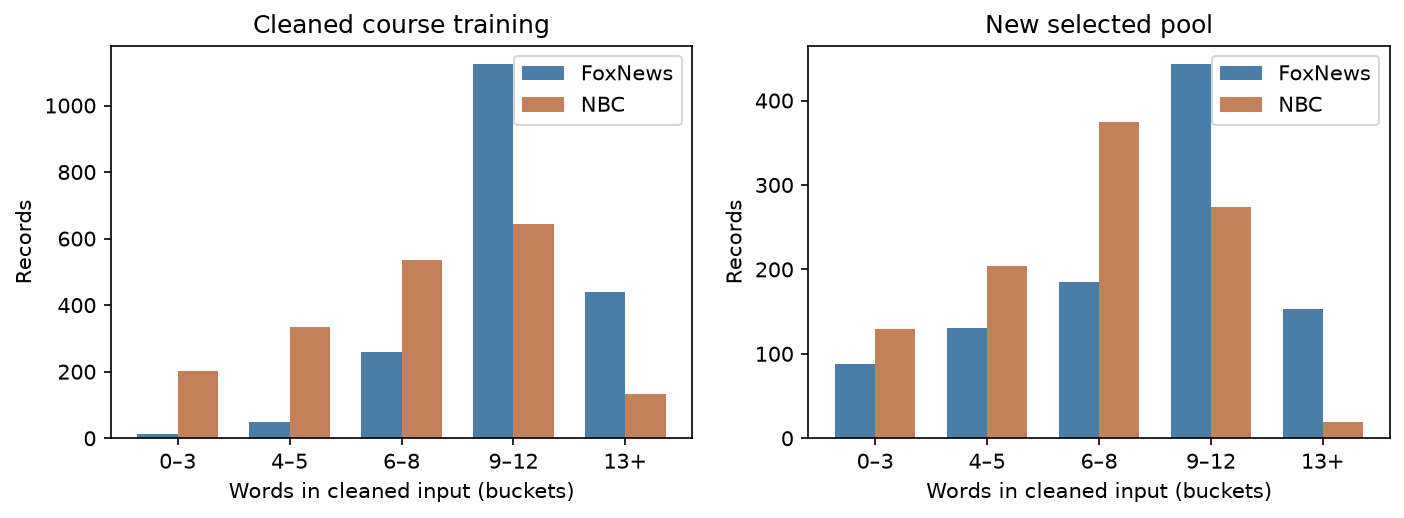

In [10]:
if RUN_FULL_HISTORICAL_REVIEW:
    length_summary = []
    for name, frame in [("course clean", frames["course_clean"]),
                        ("new", new.rename(columns={"publisher_label": "label", "word_count": "words",
                                                    "character_count": "characters"}))]:
        for label, part in frame.groupby("label"):
            length_summary.append([name, label, len(part), int(part.words.le(3).sum()),
                                   int(part.words.le(5).sum()), int(part.characters.lt(3).sum()),
                                   round(part.words.mean(), 2)])
    display(pd.DataFrame(length_summary, columns=["pool", "publisher", "n", "words ≤3", "words ≤5",
                                                  "characters <3", "mean words"]))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for ax, name, frame in [(axes[0], "Cleaned course training", frames["course_clean"]),
                           (axes[1], "New selected pool", new_audited)]:
        buckets = ["0–3","4–5","6–8","9–12","13+"]
        positions = np.arange(len(buckets))
        for j,(label,color) in enumerate([("FoxNews","#1d5d91"),("NBC","#b46030")]):
            words = frame.loc[frame.label.eq(label),"words"]
            counts = pd.cut(words,[-1,3,5,8,12,np.inf],labels=buckets).value_counts().reindex(buckets)
            assert counts.sum() == len(words)
            ax.bar(positions+(j-.5)*.36,counts,width=.36,label=label,color=color,alpha=.8)
        ax.set(title=name, xlabel="Words in cleaned input (buckets)", ylabel="Records",
               xticks=positions,xticklabels=buckets)
        ax.legend()
    show_figure(fig)

publisher_label,FoxNews,NBC
year,,
2012,1,0
2017,0,2
2018,0,1
2019,0,2
2020,0,57
2021,12,57
2022,225,187
2023,205,175
2024,202,182


publisher_label,FoxNews,NBC
page_format,,
article,807,426
gallery,5,92
live,95,84
shopping,93,192
video,0,206


label,FoxNews,NBC
topic,,
business,175,178
culture,35,5
health,10,3
lifestyle,44,5
media,59,0
politics,97,61
science_tech,19,11
sports,66,8
unknown,210,419


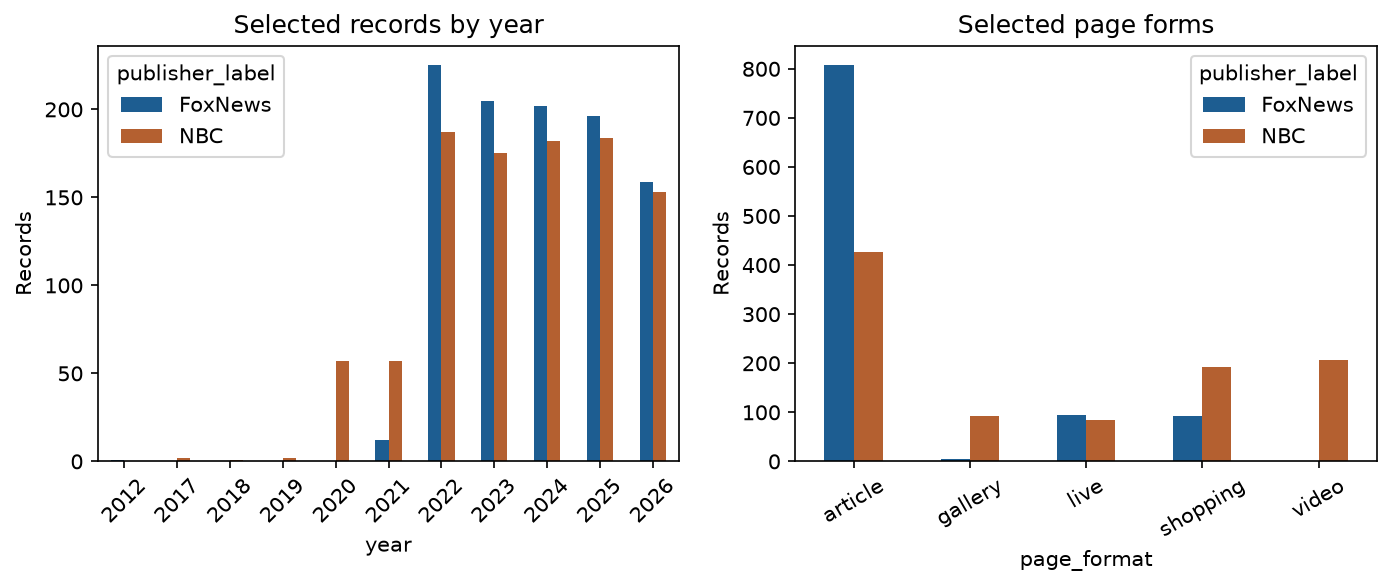

Both publishers cover all 58 months; coverage does not imply uniform sampling.


In [11]:
if RUN_FULL_HISTORICAL_REVIEW:
    years = new.assign(year=new.published_month.str[:4]).groupby(["year", "publisher_label"]).size().unstack(fill_value=0)
    forms = new.groupby(["page_format", "publisher_label"]).size().unstack(fill_value=0)
    topics = new_audited.groupby(["topic", "label"]).size().unstack(fill_value=0)
    display(years)
    display(forms)
    display(topics)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    years.plot.bar(ax=axes[0], color=["#1d5d91", "#b46030"], rot=45, title="Selected records by year")
    forms.plot.bar(ax=axes[1], color=["#1d5d91", "#b46030"], rot=30, title="Selected page forms")
    for ax in axes:
        ax.set_ylabel("Records")
    show_figure(fig)
    months = new.loc[new.published_month.between("2022-01", "2026-10")].groupby(
        ["published_month", "publisher_label"]).size().unstack(fill_value=0)
    assert months.shape == (58, 2) and months.gt(0).all().all()
    print("Both publishers cover all 58 months; coverage does not imply uniform sampling.")

## 10. Collection implementation (disabled)

Official index discovery → source restriction → URL-to-text conversion → overlap screening →
official page verification → date/form evidence → targeted selection → event review.
The bounded implementation below consolidates the public-page parsing and provenance logic.
Re-fetching current pages cannot guarantee reproduction of historical snapshots or selection.
Exact old discovery jobs, matching and review code are preserved in the source archive.

In [ ]:
from html.parser import HTMLParser
from urllib.parse import urlparse, urljoin
import urllib.request
import xml.etree.ElementTree as ET
import hashlib
import time
import datetime

class PageMetadata(HTMLParser):
    def __init__(self):
        super().__init__()
        self.links, self.canonical, self.meta, self.structured = [], "", {}, []
        self.script = None
    def handle_starttag(self, tag, attrs):
        d = dict(attrs)
        if tag == "a" and "href" in d:
            self.links.append(d["href"])
        if tag == "link" and "canonical" in d.get("rel", "").split():
            self.canonical = d.get("href", "")
        if tag == "meta":
            self.meta[d.get("property", d.get("name", ""))] = d.get("content", "")
        if tag == "script" and d.get("type") == "application/ld+json":
            self.script = ""
    def handle_data(self, data):
        if self.script is not None:
            self.script += data
    def handle_endtag(self, tag):
        if tag == "script" and self.script is not None:
            try:
                self.structured.append(json.loads(self.script))
            except ValueError:
                pass
            self.script = None

def official_url(url):
    return urlparse(url).scheme == "https" and (urlparse(url).hostname or "").lower() in {
        "foxnews.com", "www.foxnews.com", "nbcnews.com", "www.nbcnews.com"}

class OfficialRedirects(urllib.request.HTTPRedirectHandler):
    def redirect_request(self, req, fp, code, msg, headers, newurl):
        if not official_url(newurl):
            raise ValueError("Redirect outside approved publishers")
        return super().redirect_request(req, fp, code, msg, headers, newurl)

def fetch_official(url, *, enabled=False, pause_seconds=.5, max_bytes=10_000_000):
    if not enabled:
        raise RuntimeError("Collection requires an explicit new run.")
    if not official_url(url):
        raise ValueError("Only official Fox News/NBC URLs are accepted.")
    time.sleep(pause_seconds)
    request = urllib.request.Request(url, headers={"User-Agent": "DragonThree-CIS5190-research/2.0"})
    with urllib.request.build_opener(OfficialRedirects()).open(request, timeout=25) as response:
        body = response.read(max_bytes + 1)
        if len(body) > max_bytes:
            raise ValueError("Response exceeded size limit")
        log = {"request_url": url, "final_url": response.url, "http_status": response.status,
               "collected_at": datetime.datetime.now(datetime.timezone.utc).isoformat(),
               "response_sha256": hashlib.sha256(body).hexdigest()}
    return body.decode("utf-8", errors="replace"), log

def discover_links(body, discovery_url):
    if body.lstrip().startswith("<?xml") or "<urlset" in body or "<sitemapindex" in body:
        links = [n.text for n in ET.fromstring(body).iter() if n.tag.rsplit("}", 1)[-1] == "loc"]
    else:
        parser = PageMetadata()
        parser.feed(body)
        links = parser.links
    # Sitemap-index entries require another discovery pass; they are not news records.
    return sorted({urljoin(discovery_url, u) for u in links if u and official_url(urljoin(discovery_url, u))})

def structured_objects(value):
    if isinstance(value, list):
        for item in value:
            yield from structured_objects(item)
    elif isinstance(value, dict):
        yield value
        if "@graph" in value:
            yield from structured_objects(value["@graph"])

def verify_page(url, discovery_url, *, enabled=False):
    body, response = fetch_official(url, enabled=enabled)
    page = PageMetadata()
    page.feed(body)
    canonical = urljoin(response["final_url"], page.canonical or response["final_url"])
    if not official_url(canonical) or label_from_url(canonical) != label_from_url(url):
        raise ValueError("Canonical publisher is inconsistent")
    items = list(structured_objects(page.structured))
    headline = next((x["headline"] for x in items if x.get("headline")), page.meta.get("og:title", ""))
    published = next((x["datePublished"] for x in items if x.get("datePublished")), "")
    uploaded = next((x["uploadDate"] for x in items if x.get("uploadDate")), "")
    text = url_to_text(url)
    return {"source_url": url, "canonical_url": canonical, "discovery_url": discovery_url,
            "publisher_label": label_from_url(url), "model_text": text, "raw_headline": headline,
            "word_count": len(text.split()), "character_count": len(text),
            "published_at": published or uploaded, "date_evidence": "datePublished" if published else
            "uploadDate" if uploaded else "unknown", "response": response,
            "review_status": "candidate; still requires overlap/title/date/form/event review"}

DISCOVERY_URLS = []
if RUN_COLLECTION:
    if not DISCOVERY_URLS:
        raise ValueError("Supply a bounded official discovery list.")
    discovered = []
    for index_url in DISCOVERY_URLS:
        body, record = fetch_official(index_url, enabled=True)
        discovered.extend({"url": u, "discovery_url": index_url} for u in discover_links(body, index_url))
    display(pd.DataFrame(discovered))
else:
    print("No website requests made. Section 7 shows saved verification evidence.")

## 11. Pool lineage and limitations

Collected records, fitted records, internal selection panels, and development sets have different roles.

In [ ]:
display(pd.DataFrame([
    ["Original v1–v5 validated", "3,849 course", "951 course development"],
    ["Cleaned v3 reference", "3,730 course", "951 / 306 / 200 reused development panels"],
    ["Paired v4 candidate", "3,730 course + 800 paired", "paired gains; historical external does not improve"],
    ["New-data v3", "3,730 course + 2,000 new; new weight .1", "old 2,366 is internal selection only"],
    ["Latest A", "course features/classifier", "external INTERNAL labels inform parameter selection"],
    ["Latest C", "course vocabulary; joint IDF/classifier", "parameters locked; no final export or dev score"],
], columns=["condition", "fitting scope", "evaluation/selection role"]))
display(pd.DataFrame([{"input": name} for name in sorted(READS)]))

The registered 410-record sealed holdout is not included, accessed, hashed or used for selection.
The teacher's hidden test is separate and its composition remains unknown.
Original collection summaries saying “not trained” predate the later new-data experiment;
Notebook 03 gives the subsequent result and the still-incomplete latest study separately.
Authors/form/topic are audit variables, not guaranteed inference inputs. Unknown annotations remain
unknown. Complete source locations are in the package manifest and collection source index.

## 12. Archived collection and event-pairing source

These seven historical implementations document how the supplementary and event-paired datasets were assembled. The source is provided for inspection. See [historical experiments](02_Historical_Experiments_and_Results.ipynb) for modeling results.


### assemble.py.txt

<a id="source-quality-pipeline-experiments-data-supplement-2026-10-29-assemble-py"></a>

quality_pipeline/experiments/data_supplement_2026-10-29/assemble.py

**What this code does.** Assembles the supplementary dataset from collected candidates. It uses TF–IDF similarity to compare headlines and applies the selection rules before writing the assembled records.

````python
"""Deduplicate, balance coverage and conservatively group verified new candidates."""
import os
for k in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','VECLIB_MAXIMUM_THREADS'):os.environ[k]='1'
from collect import *
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def assemble():
 requests=jl(ROOT/'to_verify.jsonl')+jl(ROOT/'special_to_verify.jsonl')+jl(ROOT/'extra_to_verify.jsonl')
 requests=list({r['url']:r for r in requests}.values())
 missing=[r['url'] for r in requests if not (ROOT/'verified'/(digest(r['url'])+'.json')).exists()]
 if missing:raise RuntimeError('Verification still running: '+str(len(missing)))
 rows=[json.loads((ROOT/'verified'/(digest(r['url'])+'.json')).read_text()) for r in requests]
 overrides=json.loads((ROOT/'topic_review_overrides.json').read_text()) if (ROOT/'topic_review_overrides.json').exists() else {}
 for r in rows:
  if r['verification_status']=='publisher_metadata_verified':
   r['topic'],r['topic_method']=topic(r['canonical_url'],r['headline'])
   rid=digest(canonical(r['canonical_url']))[:20]
   if rid in overrides:r['topic']=overrides[rid]['topic'];r['topic_method']='assistant_headline_review_metaphor_correction'
 train,dev=existing();known=train+dev
 known_urls={canonical(r['url']) for r in known};known_texts={norm(model_text(r['url'])) for r in known}
 seen_urls=set();seen_texts={};accepted=[];excluded=[]
 for r in rows:
  reason=''
  if r['verification_status']!='publisher_metadata_verified':reason='verification_failed: '+r.get('error','unknown')
  else:
   u=canonical(r['canonical_url']);t=norm(r['model_text'])
   if u in known_urls:reason='existing_canonical_url'
   elif t in known_texts:reason='existing_model_text'
   elif u in seen_urls:reason='within_batch_canonical_duplicate'
   elif t in seen_texts:
    if seen_texts[t]['publisher']==r['publisher']:reason='within_batch_model_text_duplicate'
    else:reason='cross_publisher_identical_input_conflict';seen_texts[t]['input_conflict']=True
   if not reason:seen_urls.add(u);seen_texts[t]=r;accepted.append(r)
  if reason:excluded.append({'url':r['url'],'publisher':r['publisher'],'reason':reason})
 cleaned=[]
 for r in accepted:
  if r.get('input_conflict'):excluded.append({'url':r['url'],'publisher':r['publisher'],'reason':'cross_publisher_identical_input_conflict'})
  else:cleaned.append(r)
 accepted=cleaned
 # Strict near-text dedup against approved train/development only, not any final test.
 ktexts=sorted(t for t in known_texts if t);ntexts=[norm(r['model_text']) for r in accepted]
 vec=TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),max_features=160000,dtype=np.float32)
 mat=vec.fit_transform(ktexts+ntexts);oldmat=mat[:len(ktexts)];newmat=mat[len(ktexts):]
 cleaned=[]
 for start in range(0,len(accepted),200):
  sim=cosine_similarity(newmat[start:start+200],oldmat)
  for j,r in enumerate(accepted[start:start+200]):
   idx=int(sim[j].argmax());score=float(sim[j,idx]);a=set(norm(r['model_text']).split());b=set(ktexts[idx].split());jac=len(a&b)/max(1,len(a|b))
   if r['words']>=6 and score>=.92 and jac>=.65:excluded.append({'url':r['url'],'publisher':r['publisher'],'reason':'near_duplicate_of_approved_train_or_dev','similarity':score})
   else:cleaned.append(r)
 accepted=cleaned
 # Coverage selection; sources balanced when sufficiently many genuine rows exist.
 selected=[];selected_urls=set();selection_counts=Counter()
 def take(pool,n,pub):
  pool=[r for r in pool if r['publisher']==pub and r['url'] not in selected_urls]
  buckets=defaultdict(list)
  for r in pool:buckets[r.get('published_month') or 'unknown'].append(r)
  for rs in buckets.values():rs.sort(key=lambda r:digest(r['url']+'final5190'))
  added=0
  while added<n and sum(r['publisher']==pub for r in selected)<1000:
   keys=[k for k,v in buckets.items() if v]
   if not keys:break
   k=min(keys,key=lambda k:(selection_counts[(pub,k)],k))
   r=buckets[k].pop();selected.append(r);selected_urls.add(r['url']);selection_counts[(pub,k)]+=1;added+=1
 for pub in ('FoxNews','NBC'):
  pool=[r for r in accepted if r['publisher']==pub]
  # One verified record per month before targeted sampling; use real publication, not sitemap dates.
  months=sorted({r.get('published_month') for r in pool if r.get('published_month') and '2022-01'<=r['published_month']<='2026-10'})
  for m in months:take([r for r in pool if r.get('published_month')==m],1,pub)
  take([r for r in pool if r['words']<=3],80 if pub=='FoxNews' else 65,pub)
  take([r for r in pool if r['words']<=5],70 if pub=='FoxNews' else 30,pub)
  quotas={'gallery':45 if pub=='FoxNews' else 75,'live':70,'shopping':65 if pub=='FoxNews' else 130,'video':160}
  for form,q in quotas.items():take([r for r in pool if r['page_format']==form],q,pub)
  for top in ('business','weather_environment'):take([r for r in pool if r['topic']==top],180,pub)
  take([r for r in pool if r.get('published_month') and r['published_month']>='2022-01'],1000,pub)
  take(pool,1000,pub)
 # Conservative automatic event/near-duplicate groups. Not human-confirmed pairs.
 texts=[norm(r['headline']) for r in selected]
 tf=TfidfVectorizer(ngram_range=(1,2),stop_words='english',sublinear_tf=True,dtype=np.float32)
 x=tf.fit_transform(texts);sims=cosine_similarity(x);parents=list(range(len(selected)));edges=[]
 def find(i):
  while parents[i]!=i:parents[i]=parents[parents[i]];i=parents[i]
  return i
 def union(i,j):
  a,b=find(i),find(j)
  if a!=b:parents[max(a,b)]=min(a,b)
 def date(r):
  try:return datetime.date.fromisoformat(r['published_at'][:10])
  except (TypeError,ValueError):return None
 dates=[date(r) for r in selected]
 for i in range(len(selected)):
  for j in np.flatnonzero(sims[i,i+1:]>=.52)+i+1:
   score=float(sims[i,j]);a=set(texts[i].split());b=set(texts[j].split());jac=len(a&b)/max(1,len(a|b))
   gap=abs((dates[i]-dates[j]).days) if dates[i] and dates[j] else None
   if (score>=.82 and jac>=.55) or (gap is not None and gap<=3 and score>=.52 and len(a&b)>=4):
    union(i,int(j));edges.append({'left_url':selected[i]['canonical_url'],'right_url':selected[j]['canonical_url'],'headline_similarity':round(score,5),'days_apart':gap,'method':'automatic_conservative_grouping','review_status':'not_human_confirmed'})
 reviewed_pairs=[]
 if (ROOT/'pair_review_decisions.json').exists():
  byid={digest(canonical(r['canonical_url']))[:20]:i for i,r in enumerate(selected)}
  for d in json.loads((ROOT/'pair_review_decisions.json').read_text()):
   if d['decision']!='group_related_event':continue
   assert d['fox_id'] in byid and d['nbc_id'] in byid
   i,j=byid[d['fox_id']],byid[d['nbc_id']];union(i,j);reviewed_pairs.append(d)
   edges.append({'left_url':selected[i]['canonical_url'],'right_url':selected[j]['canonical_url'],'headline_similarity':d['similarity'],'days_apart':d['gap_days'],'method':'assistant_title_and_date_related_event_review','review_status':'related_event_not_full_article_annotation'})
 groups=defaultdict(list)
 for i,r in enumerate(selected):groups[find(i)].append(i)
 ids={g:'new-'+digest('|'.join(sorted(canonical(selected[i]['canonical_url']) for i in ix)))[:16] for g,ix in groups.items()}
 minimal=[];evidence=[]
 for i,r in enumerate(selected):
  evid={'topic':{'method':r['topic_method'],'status':'inferred'},'page_format':{'method':'url_and_publisher_structured_metadata','publisher_page_type':r.get('publisher_page_type',''),'structured_types':r['structured_types']},'published_month':{'method':r['date_method'],'published_at':r.get('published_at'),'status':'verified' if r.get('published_at') else 'unknown'}}
  out={'record_id':digest(canonical(r['canonical_url']))[:20],'source_url':r['canonical_url'],'publisher_label':r['publisher'],'model_text':r['model_text'],'word_count':r['words'],'character_count':r['characters'],'raw_headline':r['headline'],'group_id':ids[find(i)],'split':'candidate_train','topic':r['topic'],'page_format':r['page_format'],'published_month':r.get('published_month'),'batch_id':'essential_supplement_2026-10-29','verification_status':'publisher_metadata_verified','metadata_evidence':evid}
  minimal.append(out)
  evidence.append({'record_id':out['record_id'],'request_url':r['url'],'canonical_url':r['canonical_url'],'discovery_url':r.get('directory_url'),'http_status':r['http_status'],'response_sha256':r['response_sha256'],'collected_at':r['collected_at'],'selection_reason':r.get('selection_reason'),'metadata_evidence':evid,'grouping_status':'automatic_requires_review_before_event_CV'})
 writejl(ROOT/'new_training_candidates.jsonl',minimal)
 savecsv(ROOT/'new_training_candidates.csv',[{**r,'metadata_evidence':json.dumps(r['metadata_evidence'],ensure_ascii=False)} for r in minimal])
 savecsv(ROOT/'new_candidate_urls.csv',[{'url':r['source_url']} for r in minimal])
 writejl(ROOT/'source_evidence.jsonl',evidence);writejl(ROOT/'excluded_records.jsonl',excluded);writejl(ROOT/'automatic_group_edges.jsonl',edges)
 writejl(ROOT/'verified_reserve.jsonl',[r for r in accepted if r['url'] not in selected_urls])
 assert len({canonical(r['source_url']) for r in minimal})==len(minimal)
 assert len({norm(r['model_text']) for r in minimal})==len(minimal)
 assert not ({canonical(r['source_url']) for r in minimal}&known_urls)
 assert not ({norm(r['model_text']) for r in minimal}&known_texts)
 assert all(publisher(r['source_url'])==r['publisher_label'] and model_text(r['source_url'])==r['model_text'] for r in minimal)
 report={'as_of':ASOF,'requested_range':[1000,2000],'selected_new_records':len(minimal),'verified_requests':sum(r['verification_status']=='publisher_metadata_verified' for r in rows),'attempted_verifications':len(rows),'verified_eligible_after_dedup':len(accepted),'reserve_not_in_delivered_batch':len(accepted)-len(minimal),'source_counts':dict(Counter(r['publisher_label'] for r in minimal)),'year_counts':dict(sorted(Counter((r['published_month'] or 'unknown')[:4] for r in minimal).items())),'by_source':{},'excluded_reasons':dict(Counter(r['reason'] for r in excluded)),'automatic_event_groups':len(groups),'groups_with_multiple_rows':sum(len(v)>1 for v in groups.values()),'grouping_caveat':'Automated conservative title/date grouping, not verified event pairs. Review before training CV; no old split modified.','topic_caveat':'Coarse rule-inferred labels; publisher/date verification is stronger than semantic topic annotation.','training_status':'New candidate pool only. No training, performance claim or merge into existing train/dev.','known_exact_url_overlap':0,'known_exact_model_input_overlap':0,'near_duplicate_filter':'char TF-IDF cosine>=.92 and token Jaccard>=.65 for >=6-word inputs against approved train/dev','final_test_accessed':False,'unknown_final_overlap':'Not checked; final test remains sealed.','opened_data_files':sorted(READS)}
 for pub in ('FoxNews','NBC'):
  a=[r for r in minimal if r['publisher_label']==pub]
  report['by_source'][pub]={'n':len(a),'topics':dict(Counter(r['topic'] for r in a)),'forms':dict(Counter(r['page_format'] for r in a)),'years':dict(sorted(Counter((r['published_month'] or 'unknown')[:4] for r in a).items())),'months':dict(sorted(Counter(r['published_month'] or 'unknown' for r in a).items())),'one_to_three_words':sum(1<=r['word_count']<=3 for r in a),'strictly_less_than_three_words':sum(1<=r['word_count']<3 for r in a),'one_to_five_words':sum(1<=r['word_count']<=5 for r in a),'strictly_less_than_three_characters':sum(0<r['character_count']<3 for r in a),'zero_length_inputs':sum(r['character_count']==0 for r in a)}
 report['assistant_reviewed_related_event_pairs']=len(reviewed_pairs)
 report['grouping_caveat']='Automatic near-text/template grouping plus assistant title/date review of selected related events; not exhaustive independent-event labels. Review further before training CV; old splits unchanged.'
 dump(ROOT/'collection_summary.json',report)
 print(json.dumps({k:v for k,v in report.items() if k not in ('opened_data_files','by_source')},ensure_ascii=False,indent=2),flush=True)
 print(json.dumps({p:{k:v for k,v in s.items() if k!='months'} for p,s in report['by_source'].items()},ensure_ascii=False,indent=2),flush=True)

if __name__=='__main__':
 t=time.perf_counter();c=time.process_time();assemble();dump(ROOT/'assembly_timing.json',{'wall_seconds':time.perf_counter()-t,'cpu_seconds':time.process_time()-c,'final_test_accessed':False})

````


### collect.py.txt

<a id="source-quality-pipeline-experiments-data-supplement-2026-10-29-collect-py"></a>

quality_pipeline/experiments/data_supplement_2026-10-29/collect.py

**What this code does.** Defines the main collection workflow. It discovers candidates on publisher pages, normalizes URLs, extracts the text used by the model, and verifies selected records and their metadata.

````python
"""Train-pool-only publisher metadata collection. No bodies, authors, models or final tests."""
import os,sys,json,csv,re,hashlib,time,ssl,calendar,datetime,html,threading
from pathlib import Path
from collections import Counter,defaultdict
from urllib.parse import urlsplit,urljoin,unquote
from html.parser import HTMLParser
import urllib.request,concurrent.futures,xml.etree.ElementTree as ET
import certifi
ROOT=Path(__file__).resolve().parent
PIPE=ROOT.parents[1]
PROJECT=Path('/path/to/local/Desktop/2026 Fall/CIS 5190/Final Project')
ALLOWED={PIPE/'training/training_metadata.csv',PROJECT/'baseline/data/train.csv',PROJECT/'baseline/data/val.csv',PIPE/'data/external_dev_urls.csv',ROOT.parent/'paired_news_v4_2026-10-28/paired_train.csv',ROOT.parent/'paired_news_v4_2026-10-28/paired_confirmation.csv'}
READS=set()
def guard(event,args):
 if event!='open' or not isinstance(args[0],(str,bytes,os.PathLike)):return
 p=Path(os.fsdecode(args[0])).absolute();mode=args[1];flags=args[2]
 reading=not ((mode and any(x in mode for x in 'wax')) or flags&os.O_WRONLY)
 if 'holdout' in p.name or p.name=='external_metadata.csv':raise PermissionError('Sealed/mixed data blocked')
 if reading and p.suffix in ('.csv','.jsonl'):
  if ROOT not in p.parents and p not in ALLOWED:raise PermissionError('Unapproved data blocked: '+str(p))
  READS.add(str(p))
sys.addaudithook(guard)
UA='DragonThree-CIS5190-research/1.1 (public headline metadata; OpenAI Codex)'
CTX=ssl.create_default_context(cafile=certifi.where())
ASOF='2026-10-29'
def dump(p,v):Path(p).write_text(json.dumps(v,ensure_ascii=False,indent=2)+'\n')
def jl(p):return [json.loads(x) for x in Path(p).read_text().splitlines() if x.strip()] if Path(p).exists() else []
def writejl(p,rows):Path(p).write_text(''.join(json.dumps(x,ensure_ascii=False)+'\n' for x in rows))
def readcsv(p):
 with Path(p).open(encoding='utf-8-sig',newline='') as f:return list(csv.DictReader(f))
def savecsv(p,rows):
 if not rows:return
 with Path(p).open('w',newline='') as f:
  w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
def digest(x):return hashlib.sha256(x.encode()).hexdigest()
def canonical(u):
 p=urlsplit(u);return 'https://'+(p.hostname or '').lower().removeprefix('www.')+p.path.rstrip('/').removesuffix('.amp')
def publisher(u):
 h=(urlsplit(u).hostname or '').lower()
 return 'FoxNews' if h in ('www.foxnews.com','foxnews.com') else 'NBC' if h in ('www.nbcnews.com','nbcnews.com') else ''
def model_text(u):
 seg=[x for x in urlsplit(u).path.split('/') if x];last=unquote(seg[-1]) if seg else ''
 last=re.sub(r'\.(html?|shtml|php)$','',last,flags=re.I)
 return ' '.join(x for x in re.split('[-_]+',last) if x and not re.search(r'\d',x))
def norm(s):return ' '.join(re.findall('[a-z0-9]+',s.lower()))
def pathform(u):
 p=urlsplit(u).path.lower()
 if re.search(r'/(video|videos)/',p):return 'video'
 if re.search(r'/(select|shopping|deals)/',p):return 'shopping'
 if re.search(r'/(live-blog|live-news|live)/',p):return 'live'
 if re.search(r'/(slideshow|picture-gallery|photos|photo)/',p):return 'gallery'
 if re.search(r'/20\d\d-(?:primary-)?elections/',p) and p.endswith(('-results','/calendar','/delegate-tracker')):return 'results_calendar'
 return 'article'
TOPICS={'politics':'politics','official-polls':'politics','us':'us_society','us-news':'us_society','crime-courts':'us_society','education':'us_society','nbcblk':'us_society','nbc-out':'us_society','latino':'us_society','asian-america':'us_society','world':'world','world-news':'world','business':'business','economy':'business','real-estate':'business','sports':'sports','olympics':'sports','media':'media','entertainment':'culture','pop-culture':'culture','lifestyle':'lifestyle','food':'lifestyle','food-drink':'lifestyle','travel':'lifestyle','auto':'lifestyle','better':'lifestyle','science':'science_tech','tech':'science_tech','technology':'science_tech','mach':'science_tech','space':'science_tech','health':'health','weather':'weather_environment'}
WEATHER=r'\b(hurricane|tornado|tornadoes|flood|flooding|floods|snowstorm|blizzard|heatwave|heat wave|wildfire|wildfires|winter storm|tropical storm|atmospheric river|weather|drought|record heat|storm surge|thunderstorm|climate change|climate crisis)\b'
BUSINESS=r'\b(inflation|recession|economy|economic|unemployment|jobless|interest rates?|federal reserve|stock market|wall street|earnings|mortgage|consumer prices?|cost of living|bankruptcy|bankrupt|layoffs|supply chain|gas prices?|minimum wage|tariffs?|housing market)\b'
def topic(u,title=''):
 text=norm(title or model_text(u));segs=[x for x in urlsplit(u).path.lower().split('/') if x]
 sec=segs[1] if segs and segs[0]=='news' and len(segs)>1 else segs[0] if segs else ''
 weather_text=re.sub(r'(?:spreading )?like wildfire','',text)
 if re.search(r'\b(immigrants?|migrants?|fentanyl|tips|threats|ads|advertising|retirements|candidates|officers|new routes|data centers|twitter|social media|flood the system|flooding the zone|hamas|farmers)\b',weather_text):
  weather_text=re.sub(r'\bflood(?:ing|s)?\b','',weather_text)
 if re.search(WEATHER,weather_text):return 'weather_environment','headline_rule_v2_metaphor_filter'
 if re.search(BUSINESS,text) and pathform(u)!='shopping':return 'business','headline_rule_v2'
 return TOPICS.get(sec,'unknown'),'url_section_rule'
class Tags(HTMLParser):
 def __init__(self):super().__init__();self.links=[];self.current=None;self.canonical='';self.meta={};self.ld=[];self.script=None
 def handle_starttag(self,t,a):
  d=dict(a)
  if t=='a' and 'sitemap-grid-link' in d.get('class',''):self.current=[d.get('href',''),'']
  if t=='link' and 'canonical' in d.get('rel','').split():self.canonical=d.get('href','')
  if t=='meta':self.meta[d.get('property',d.get('name',''))]=d.get('content','')
  if t=='script' and d.get('type')=='application/ld+json':self.script=''
 def handle_data(self,s):
  if self.current is not None:self.current[1]+=s
  if self.script is not None:self.script+=s
 def handle_endtag(self,t):
  if t=='a' and self.current is not None:self.links.append(self.current);self.current=None
  if t=='script' and self.script is not None:
   try:self.ld.append(json.loads(self.script))
   except ValueError:pass
   self.script=None
def objects(o):
 if isinstance(o,list):
  for v in o:yield from objects(v)
 elif isinstance(o,dict):
  if '@type' in o:yield o
  if '@graph' in o:yield from objects(o['@graph'])
def types(o):
 t=o.get('@type',[]);t=[t] if isinstance(t,str) else t
 return ['ImageGallery' if v=='imageGallery' else v for v in t]
LOCKS=defaultdict(threading.Lock);LAST=defaultdict(float)
def fetch(u):
 host=urlsplit(u).netloc
 with LOCKS[host]:
  delay=.22-(time.monotonic()-LAST[host])
  if delay>0:time.sleep(delay)
  LAST[host]=time.monotonic()
 started=time.perf_counter()
 req=urllib.request.Request(u,headers={'User-Agent':UA})
 with urllib.request.urlopen(req,context=CTX,timeout=25) as res:
  raw=res.read(10_000_001)
  if len(raw)>10_000_000:raise ValueError('Response too large')
  return raw.decode('utf-8',errors='replace'),{'request_url':u,'final_url':res.url,'http_status':res.status,'response_sha256':hashlib.sha256(raw).hexdigest(),'response_bytes':len(raw),'collected_at':datetime.datetime.now(datetime.timezone.utc).isoformat(),'wall_seconds':time.perf_counter()-started}
def directory(job):
 u,pub,month,kind=job;fp=ROOT/'directories'/(digest(u)+'.json')
 if fp.exists():return json.loads(fp.read_text())
 try:
  body,log=fetch(u);rows=[]
  if pub=='NBC':
   tree=ET.fromstring(body);ns={'s':'http://www.sitemaps.org/schemas/sitemap/0.9','v':'http://www.google.com/schemas/sitemap-video/1.1'}
   for ent in tree:
    link=ent.findtext('s:loc','',ns)
    if publisher(link)!=pub:continue
    rows.append({'url':link,'publisher':pub,'discovery_title':ent.findtext('v:video/v:title','',ns),'directory_month':month,'directory_url':u,'lastmod_hint':ent.findtext('s:lastmod','',ns),'video_publication_hint':ent.findtext('v:video/v:publication_date','',ns)})
  else:
   tags=Tags();tags.feed(body)
   for link,title in tags.links:
    link=urljoin(u,link)
    if publisher(link)!=pub:continue
    rows.append({'url':link,'publisher':pub,'discovery_title':' '.join(title.split()),'directory_month':month,'directory_url':u})
  log['rows']=len(rows);result={'rows':rows,'log':log}
 except Exception as e:result={'rows':[],'log':{'request_url':u,'error':str(e)}}
 dump(fp,result);return result
def discovery(extra=False):
 (ROOT/'directories').mkdir(exist_ok=True);jobs=[]
 if extra:
  for y in range(2014,2022):
   for m in (1,4,7,10):
    for d in (5,19):jobs.append((f'https://www.foxnews.com/html-sitemap/{y}/{calendar.month_name[m].lower()}/{d}','FoxNews',f'{y}-{m:02d}','article'))
 else:
  for y in range(2022,2027):
   for m in range(1,13 if y<2026 else 11):
    month=f'{y}-{m:02d}'
    for kind in (['article','video'] if m%2 else ['article']):jobs.append((f'https://www.nbcnews.com/sitemap/nbcnews/sitemap-{month}-{kind}.xml','NBC',month,kind))
    for d in (5,19):jobs.append((f'https://www.foxnews.com/html-sitemap/{y}/{calendar.month_name[m].lower()}/{d}','FoxNews',month,'article'))
 with concurrent.futures.ThreadPoolExecutor(4) as ex:
  for i,x in enumerate(ex.map(directory,jobs)):
   if i%10==0:print('DISCOVER',i+1,len(jobs),x['log']['request_url'],len(x['rows']),x['log'].get('error','OK'),flush=True)
 merged={};logs=[]
 for f in sorted((ROOT/'directories').glob('*.json')):
  x=json.loads(f.read_text());logs.append(x['log'])
  for r in x['rows']:merged.setdefault(canonical(r['url']),r)
 writejl(ROOT/'discovery_records.jsonl',merged.values());dump(ROOT/'discovery_log.json',logs)
 print('DISCOVERY_TOTAL',len(merged),dict(Counter(r['publisher'] for r in merged.values())),flush=True)
def discover_special():
 body,log=fetch('https://www.nbcnews.com/sitemap/nbcnews/sitemap-index')
 links=[x.text for x in ET.fromstring(body).findall('.//{http://www.sitemaps.org/schemas/sitemap/0.9}loc')]
 jobs=[('https://www.nbcnews.com/sitemap/nbcnews/sitemap-select.xml','NBC','unknown','shopping')]
 for u in links:
  m=re.search(r'sitemap-(20\d\d-\d\d)-slideshow.xml$',u)
  if m and '2022-01'<=m[1]<='2026-10':jobs.append((u,'NBC',m[1],'gallery'))
 with concurrent.futures.ThreadPoolExecutor(2) as ex:results=list(ex.map(directory,jobs))
 records={}
 for x in results:
  for r in x['rows']:records.setdefault(canonical(r['url']),r)
 writejl(ROOT/'special_discovery_records.jsonl',records.values());dump(ROOT/'special_discovery_log.json',[log]+[x['log'] for x in results])
 known_train,dev=existing();knownurls={canonical(r['url']) for r in known_train+dev};knowntexts={norm(model_text(r['url'])) for r in known_train+dev};oldurls={canonical(r['url']) for r in jl(ROOT/'to_verify.jsonl')}
 pools=defaultdict(list)
 for r in records.values():
  t=model_text(r['url'])
  if not norm(t) or canonical(r['url']) in knownurls|oldurls or norm(t) in knowntexts:continue
  r.update(model_text=t,words=len(t.split()),characters=len(t),selection_reason='special_'+pathform(r['url']),page_format_hint=pathform(r['url']),topic_hint=topic(r['url'])[0])
  pools[pathform(r['url'])].append(r)
 selected=[]
 for form,n in [('shopping',300),('gallery',150)]:
  pools[form].sort(key=lambda r:(r['words']>5,digest(r['url']+'special5190')));selected.extend(pools[form][:n])
 writejl(ROOT/'special_to_verify.jsonl',selected)
 print('SPECIAL_DISCOVERED',len(records),'SELECTED',dict(Counter(r['page_format_hint'] for r in selected)),flush=True)
def existing():
 train=readcsv(PIPE/'training/training_metadata.csv')+readcsv(ROOT.parent/'paired_news_v4_2026-10-28/paired_train.csv')+readcsv(PROJECT/'baseline/data/train.csv')
 dev=readcsv(PROJECT/'baseline/data/val.csv')+readcsv(PIPE/'data/external_dev_urls.csv')+readcsv(ROOT.parent/'paired_news_v4_2026-10-28/paired_confirmation.csv')
 return train,dev
def select():
 train,dev=existing();known=train+dev;urls={canonical(r['url']) for r in known};texts={norm(model_text(r['url'])) for r in known}
 rows=[];excluded=Counter()
 for r in jl(ROOT/'discovery_records.jsonl'):
  t=model_text(r['url']);n=norm(t)
  if canonical(r['url']) in urls:excluded['known_url']+=1;continue
  if n in texts:excluded['known_text']+=1;continue
  if not n:excluded['empty_input']+=1;continue
  r.update(model_text=t,words=len(t.split()),characters=len(t),page_format_hint=pathform(r['url']),topic_hint=topic(r['url'],r['discovery_title'])[0]);rows.append(r)
 selected={}
 def choose(pool,num,tag):
  counts=Counter();pools=defaultdict(list)
  for r in pool:pools[r['directory_month']].append(r)
  for group in pools.values():group.sort(key=lambda x:digest(x['url']+'5190'))
  added=0
  while added<num:
   progress=False
   for month in sorted(pools):
    while pools[month] and canonical(pools[month][-1]['url']) in selected:pools[month].pop()
    if pools[month] and added<num:
     r=pools[month].pop();r={**r,'selection_reason':tag};selected[canonical(r['url'])]=r;added+=1;progress=True
   if not progress:break
  return added
 for pub in ('FoxNews','NBC'):
  pool=[r for r in rows if r['publisher']==pub]
  choose([r for r in pool if r['words']<=3],100,'short_1to3_words')
  choose([r for r in pool if r['words']<=5],100 if pub=='FoxNews' else 60,'short_4to5_words')
  for form,quota in [('gallery',100),('live',120),('shopping',170),('video',180)]:choose([r for r in pool if r['page_format_hint']==form],quota,'form_'+form)
  for top in ('business','weather_environment'):choose([r for r in pool if r['topic_hint']==top],230,'topic_'+top)
  count=sum(r['publisher']==pub for r in selected.values());choose([r for r in pool if r['directory_month'][:4]>='2022'],max(0,1350-count),'year_month_coverage')
 writejl(ROOT/'to_verify.jsonl',selected.values())
 dump(ROOT/'selection_manifest.json',{'eligible_discovery':len(rows),'selected':len(selected),'by_source':dict(Counter(r['publisher'] for r in selected.values())),'by_reason':dict(Counter(r['selection_reason'] for r in selected.values())),'excluded':dict(excluded),'discovery_short_fox_1to3':sum(r['publisher']=='FoxNews' and r['words']<=3 for r in rows),'discovery_lt3_characters':sum(0<r['characters']<3 for r in rows),'final_test_accessed':False,'opened_data_files':sorted(READS)})
 print((ROOT/'selection_manifest.json').read_text(),flush=True)
def verify(r,refresh=False):
 fp=ROOT/'verified'/(digest(r['url'])+'.json')
 if fp.exists() and not refresh:return json.loads(fp.read_text())
 try:
  body,log=fetch(r['url']);tags=Tags();tags.feed(body)
  obs=[o for ld in tags.ld for o in objects(ld)]
  articles=[o for o in obs if set(types(o))&{'Article','NewsArticle','ReportageNewsArticle','LiveBlogPosting','BlogPosting'}]
  videos=[o for o in obs if 'VideoObject' in types(o)]
  galleries=[o for o in obs if 'ImageGallery' in types(o)]
  pages=[o for o in obs if set(types(o))&{'WebPage','CollectionPage','ImageGallery'}]
  f=pathform(r['url']);ob=(videos or articles or pages or [{}])[0] if f=='video' else (galleries or articles or pages or videos or [{}])[0]
  can=tags.canonical or ob.get('url') or log['final_url']
  if isinstance(can,dict):can=can.get('@id','')
  if publisher(can)!=r['publisher']:raise ValueError('Canonical publisher outside target scope')
  title=html.unescape(ob.get('headline') or ob.get('name') or tags.meta.get('og:title',''))
  if not isinstance(title,str) or not title.strip():raise ValueError('Missing publisher title')
  if title.strip().lower() in ('fox news','nbc news','page not found','access denied'):raise ValueError('Generic error or landing page')
  pubdate=ob.get('datePublished') or (ob.get('uploadDate') if f=='video' else None) or tags.meta.get('article:published_time') or tags.meta.get('dcterms.created') or ''
  date_method='structured_datePublished' if ob.get('datePublished') else 'video_uploadDate' if f=='video' and ob.get('uploadDate') else 'publisher_meta' if pubdate else 'unknown'
  if not pubdate and f=='video' and r.get('video_publication_hint'):pubdate=r['video_publication_hint'];date_method='publisher_video_sitemap_publication_date'
  if pubdate and not re.match(r'^20\d\d-\d\d-\d\d',str(pubdate)):raise ValueError('Unparseable publication date')
  if pubdate and str(pubdate)[:10]>ASOF:raise ValueError('After collection as-of date')
  t=model_text(can)
  if not norm(t):raise ValueError('Empty model input after course preprocessing')
  if len(t)>500:raise ValueError('Unusually long model input')
  if len([x for x in urlsplit(can).path.split('/') if x])<2:raise ValueError('Likely section page')
  overlap=set(norm(title).split())&set(norm(t).split())
  if not overlap:raise ValueError('Title/input mismatch')
  if not articles and not videos and not galleries and not pubdate:raise ValueError('No article/video identity or reliable publication metadata')
  form=pathform(can)
  if 'LiveBlogPosting' in types(ob):form='live'
  if 'ImageGallery' in types(ob):form='gallery'
  if tags.meta.get('pagetype','').lower() in ('slideshow','gallery') or re.search(r'"(?:contentType|articleType|pageType|type)"\s*:\s*"(?:slideshow|gallery)"',body,re.I):form='gallery'
  if form=='article' and not articles:form='other'
  top,method=topic(can,title)
  result={**r,**log,'canonical_url':can,'headline':title.strip(),'published_at':pubdate or None,'published_month':str(pubdate)[:7] if pubdate else None,'date_method':date_method,'model_text':t,'words':len(t.split()),'characters':len(t),'page_format':form,'topic':top,'topic_method':method,'structured_types':types(ob),'publisher_page_type':tags.meta.get('pagetype',''),'verification_status':'publisher_metadata_verified','metadata_evidence':{'title':'structured_headline_or_name' if ob.get('headline') or ob.get('name') else 'og:title','date':date_method,'topic':method,'form':'url_and_structured_metadata'},'article_section':ob.get('articleSection',None)}
 except Exception as e:result={**r,**(log if 'log' in locals() else {}),'verification_status':'failed','error':str(e)}
 dump(fp,result);return result
def verify_all(special=False):
 (ROOT/'verified').mkdir(exist_ok=True);rows=jl(ROOT/('special_to_verify.jsonl' if special else 'to_verify.jsonl'));counts=Counter()
 with concurrent.futures.ThreadPoolExecutor(4) as ex:
  for i,r in enumerate(ex.map(verify,rows)):
   counts[r['verification_status']]+=1
   if i%40==0:print('VERIFY',i+1,len(rows),dict(counts),flush=True)
 result=[json.loads((ROOT/'verified'/(digest(r['url'])+'.json')).read_text()) for r in rows]
 writejl(ROOT/('special_verification_records.jsonl' if special else 'verification_records.jsonl'),result)
 print('VERIFY_DONE',dict(Counter(r['verification_status'] for r in result)),dict(Counter(r.get('error','') for r in result if r['verification_status']=='failed')),flush=True)
def repair_forms():
 rows=jl(ROOT/'to_verify.jsonl')+jl(ROOT/'special_to_verify.jsonl')+jl(ROOT/'extra_to_verify.jsonl');suspects=[]
 for r in rows:
  fp=ROOT/'verified'/(digest(r['url'])+'.json')
  if not fp.exists():continue
  v=json.loads(fp.read_text())
  if v.get('verification_status')=='publisher_metadata_verified' and v['publisher']=='FoxNews' and 'publisher_page_type' not in v and (v['words']<=5 or re.search(r'mugshot|photo|picture|slideshow',v['headline'],re.I)):suspects.append(r)
  elif v['publisher']=='NBC' and pathform(v['url'])=='gallery' and v.get('error')=='No article/video identity or reliable publication metadata':suspects.append(r)
 with concurrent.futures.ThreadPoolExecutor(2) as ex:out=list(ex.map(lambda r:verify(r,True),suspects))
 dump(ROOT/'form_repair_log.json',{'rechecked':len(out),'forms':dict(Counter(r.get('page_format') for r in out))})
 print('FORM_REPAIR',len(out),flush=True)
def course_audit():
 rows=[r for r in readcsv(PIPE/'training/training_metadata.csv') if r['origin']=='course'];out=[];strata=defaultdict(list)
 for r in rows:
  u=r['url'];t=model_text(u);top,method=topic(u);v={'url':u,'publisher':publisher(u),'model_text':t,'words':len(t.split()),'characters':len(t),'topic_hint':top,'page_format_hint':pathform(u),'split':'existing_train'};out.append(v);strata[(v['publisher'],v['page_format_hint'],'short' if v['words']<=5 else 'long')].append(v)
 sample=[]
 for group in strata.values():group.sort(key=lambda r:digest(r['url']+'audit5190'))
 while len(sample)<200:
  progress=False
  for key in sorted(strata):
   if strata[key] and len(sample)<200:sample.append(strata[key].pop());progress=True
  if not progress:break
 savecsv(ROOT/'course_train_light_audit.csv',out);writejl(ROOT/'course_audit_sample.jsonl',sample)
 (ROOT/'verified').mkdir(exist_ok=True)
 with concurrent.futures.ThreadPoolExecutor(4) as ex:verified=list(ex.map(verify,sample))
 writejl(ROOT/'course_sample_verified.jsonl',verified)
 dump(ROOT/'course_audit_summary.json',{'rows':len(out),'sample':len(sample),'verified':dict(Counter(r['verification_status'] for r in verified)),'sample_years':dict(Counter((r.get('published_at') or 'unknown')[:4] for r in verified)),'sampling':'stratified by publisher, URL form and <=5 words; unweighted sample is not population year estimate','original_splits_unchanged':True,'final_test_accessed':False})
 print((ROOT/'course_audit_summary.json').read_text(),flush=True)
if __name__=='__main__':
 ROOT.mkdir(exist_ok=True);started=time.perf_counter();cpu=time.process_time();mode=sys.argv[1]
 if mode=='discover':discovery()
 elif mode=='discover_old':discovery(True)
 elif mode=='discover_special':discover_special()
 elif mode=='select':select()
 elif mode=='verify':verify_all()
 elif mode=='verify_special':verify_all(True)
 elif mode=='repair_forms':repair_forms()
 elif mode=='course_audit':course_audit()
 else:raise ValueError(mode)
 dump(ROOT/(mode+'_timing.json'),{'wall_seconds':time.perf_counter()-started,'cpu_seconds':time.process_time()-cpu,'threads':4,'final_test_accessed':False,'opened_data_files':sorted(READS)})

````


### extra_discover.py.txt

<a id="source-quality-pipeline-experiments-data-supplement-2026-10-29-extra-discover-py"></a>

quality_pipeline/experiments/data_supplement_2026-10-29/extra_discover.py

**What this code does.** Adds a discovery pass to the main collector. It reuses the collection helpers to find additional candidates for the supplementary pool.

````python
from collect import *

def run():
 rows=[];logs=[]
 u='https://www.foxnews.com/sitemap.xml?type=liveblogs'
 body,log=fetch(u);logs.append(log)
 ns={'s':'http://www.sitemaps.org/schemas/sitemap/0.9'}
 for ent in ET.fromstring(body):
  link=ent.findtext('s:loc','',ns)
  if publisher(link)!='FoxNews' or '/live-news/' not in link:continue
  last=ent.findtext('s:lastmod','',ns)
  rows.append({'url':link,'publisher':'FoxNews','discovery_title':'','directory_month':last[:7] or 'unknown','directory_url':u,'lastmod_hint':last})
 # Gallery publication is verified on-page; index month is only a discovery hint.
 u='https://www.nbcnews.com/sitemap/nbcnews/sitemap-index';body,log=fetch(u);logs.append(log)
 jobs=[]
 for x in ET.fromstring(body).findall('.//s:loc',ns):
  m=re.search(r'sitemap-(20\d\d-\d\d)-slideshow.xml$',x.text)
  if m and '2020-01'<=m[1]<'2022-01':jobs.append((x.text,'NBC',m[1],'gallery'))
 with concurrent.futures.ThreadPoolExecutor(2) as ex:
  for result in ex.map(directory,jobs):rows.extend(result['rows']);logs.append(result['log'])
 train,dev=existing();knownurls={canonical(r['url']) for r in train+dev};knowntexts={norm(model_text(r['url'])) for r in train+dev}
 selectedurls={canonical(r['url']) for r in jl(ROOT/'to_verify.jsonl')+jl(ROOT/'special_to_verify.jsonl')}
 pools=defaultdict(list)
 for r in rows:
  t=model_text(r['url'])
  if not norm(t) or canonical(r['url']) in knownurls|selectedurls or norm(t) in knowntexts:continue
  form=pathform(r['url']);r.update(model_text=t,words=len(t.split()),characters=len(t),page_format_hint=form,topic_hint=topic(r['url'])[0],selection_reason='extra_'+form)
  pools[(r['publisher'],form)].append(r)
 selected=[]
 for key,group in pools.items():
  group.sort(key=lambda r:digest(r['url']+'extra5190'))
  selected.extend(group[:150 if key[0]=='FoxNews' else 120])
 writejl(ROOT/'extra_discovery_records.jsonl',rows);writejl(ROOT/'extra_to_verify.jsonl',selected);dump(ROOT/'extra_discovery_log.json',logs)
 print('EXTRA_DISCOVERED',len(rows),'SELECTED',dict(Counter((r['publisher'],r['page_format_hint']) for r in selected)),flush=True)
 counts=Counter()
 with concurrent.futures.ThreadPoolExecutor(2) as ex:
  for i,result in enumerate(ex.map(verify,selected)):
   counts[result['verification_status']]+=1
   if i%25==0:print('EXTRA_VERIFY',i+1,len(selected),dict(counts),flush=True)
 output=[json.loads((ROOT/'verified'/(digest(r['url'])+'.json')).read_text()) for r in selected]
 writejl(ROOT/'extra_verification_records.jsonl',output)
 print('EXTRA_DONE',dict(counts),flush=True)

if __name__=='__main__':
 t=time.perf_counter();c=time.process_time();run();dump(ROOT/'extra_timing.json',{'wall_seconds':time.perf_counter()-t,'cpu_seconds':time.process_time()-c,'final_test_accessed':False})

````


### collect.py.txt

<a id="source-quality-pipeline-experiments-paired-news-v4-2026-10-28-collect-py"></a>

quality_pipeline/experiments/paired_news_v4_2026-10-28/collect.py

**What this code does.** Collects candidates for matching coverage of the same event across FoxNews and NBC. It parses publisher pages, verifies selected URLs, and checks author and byline metadata.

````python
"""Publisher-owned directory discovery; article metadata verification; no bodies stored."""
from support import *
import urllib.request,urllib.error,ssl,certifi,html,calendar,datetime,concurrent.futures
from urllib.parse import urlparse,urljoin,unquote
from html.parser import HTMLParser
import xml.etree.ElementTree as ET
CTX=ssl.create_default_context(cafile=certifi.where())
UA='DragonThree-CIS5190-research/1.0 (public headline metadata; OpenAI Codex)'
MONTHS=['2024-07','2024-08','2025-01','2025-05','2024-04']
class Tags(HTMLParser):
 def __init__(self):super().__init__();self.links=[];self.current=None;self.canonical='';self.meta={};self.ld=[];self.script=None
 def handle_starttag(self,tag,attrs):
  d=dict(attrs)
  if tag=='a' and 'sitemap-grid-link' in d.get('class',''):self.current=[d.get('href',''),'']
  if tag=='link' and d.get('rel')=='canonical':self.canonical=d.get('href','')
  if tag=='meta':self.meta[d.get('property',d.get('name',''))]=d.get('content','')
  if tag=='script' and d.get('type')=='application/ld+json':self.script=''
 def handle_data(self,s):
  if self.current is not None:self.current[1]+=s
  if self.script is not None:self.script+=s
 def handle_endtag(self,tag):
  if tag=='a' and self.current is not None:self.links.append(self.current);self.current=None
  if tag=='script' and self.script is not None:
   try:self.ld.append(json.loads(self.script))
   except ValueError:pass
   self.script=None
def fetch(u):
 started=time.perf_counter();req=urllib.request.Request(u,headers={'User-Agent':UA})
 with urllib.request.urlopen(req,context=CTX,timeout=20) as res:
  raw=res.read(8_000_001)
  if len(raw)>8_000_000:raise ValueError('Response too large')
  return raw.decode('utf-8',errors='replace'),{'request_url':u,'final_url':res.url,'http_status':res.status,'response_sha256':hashlib.sha256(raw).hexdigest(),'bytes':len(raw),'fetched_at':datetime.datetime.now(datetime.timezone.utc).isoformat(),'wall_seconds':time.perf_counter()-started}
def directory(job):
 u,label,month,date=job
 try:
  body,log=fetch(u);rows=[]
  if label=='NBC':
   root=ET.fromstring(body);ns={'s':'http://www.sitemaps.org/schemas/sitemap/0.9'}
   for ent in root:
    url=ent.findtext('s:loc','',ns);last=ent.findtext('s:lastmod','',ns)
    if urlparse(url).hostname!='www.nbcnews.com':continue
    text=unquote(urlparse(url).path.split('/')[-1]);text=re.sub(r'-(?:rcna|ncna|n)\d+$','',text).replace('-',' ')
    rows.append({'publisher':label,'url':url,'discovery_text':text,'directory_month':month,'directory_date_hint':last[:10] if last.startswith(month) else '', 'directory_url':u,'directory_sha256':log['response_sha256']})
  else:
   tags=Tags();tags.feed(body)
   for url,title in tags.links:
    url=urljoin(u,url)
    if urlparse(url).hostname!='www.foxnews.com':continue
    if len(urlparse(url).path.split('/')[-1])<20:continue
    rows.append({'publisher':label,'url':url,'discovery_text':' '.join(title.split()),'directory_month':month,'directory_date_hint':date,'directory_url':u,'directory_sha256':log['response_sha256']})
  log['rows']=len(rows);time.sleep(.12);return rows,log
 except Exception as e:return [],{'request_url':u,'error':str(e)}
def discover():
 cache=ROOT/'directories';cache.mkdir(exist_ok=True)
 jobs=[]
 for month in MONTHS:
  y,m=map(int,month.split('-'));jobs.append((f'https://www.nbcnews.com/sitemap/nbcnews/sitemap-{month}-article.xml','NBC',month,''))
  for d in range(1,calendar.monthrange(y,m)[1]+1):jobs.append((f'https://www.foxnews.com/html-sitemap/{y}/{calendar.month_name[m].lower()}/{d}','FoxNews',month,f'{month}-{d:02d}'))
 todo=[j for j in jobs if not (cache/(hashlib.sha256(j[0].encode()).hexdigest()+'.json')).exists()]
 with concurrent.futures.ThreadPoolExecutor(4) as pool:
  for rows,log in pool.map(directory,todo):
   dump(cache/(hashlib.sha256(log['request_url'].encode()).hexdigest()+'.json'),{'rows':rows,'log':log})
   print('DIRECTORY',log['request_url'],len(rows),log.get('error','OK'),flush=True)
 records={};logs=[]
 for j in jobs:
  value=json.loads((cache/(hashlib.sha256(j[0].encode()).hexdigest()+'.json')).read_text());logs.append(value['log'])
  for r in value['rows']:records.setdefault(r['url'],r)
 write_jl(ROOT/'discovered_metadata.jsonl',records.values());dump(ROOT/'discovery_log.json',logs)
 print('DISCOVERED',len(records),flush=True)
def news_objects(obj):
 if isinstance(obj,list):
  for v in obj:yield from news_objects(v)
 elif isinstance(obj,dict):
  types=obj.get('@type',[]);types=[types] if isinstance(types,str) else types
  if any(t in ('NewsArticle','Article','ReportageNewsArticle') for t in types):yield obj
  if '@graph' in obj:yield from news_objects(obj['@graph'])
def authors(value):
 if isinstance(value,list):return [s for v in value for s in authors(v)]
 if isinstance(value,dict):return [value['name']] if value.get('name') else []
 return [str(value)] if value else []
def verify(row):
 try:
  body,log=fetch(row['url']);tags=Tags();tags.feed(body)
  objects=[x for v in tags.ld for x in news_objects(v)]
  if not objects:raise ValueError('No article structured metadata')
  obj=objects[0];canonical=tags.canonical or obj.get('url') or log['final_url']
  if isinstance(canonical,dict):canonical=canonical.get('@id','')
  expected={'FoxNews':'foxnews.com','NBC':'nbcnews.com'}[row['publisher']]
  if (urlparse(canonical).hostname or '').removeprefix('www.')!=expected:raise ValueError('Canonical publisher mismatch')
  title=html.unescape(obj.get('headline',tags.meta.get('og:title','')));date=obj.get('datePublished','');by=authors(obj.get('author',[]))
  source_credit=tags.meta.get('dc.source','')
  if not by and source_credit and source_credit.lower() not in ('fox news','foxnews','nbc news','nbcnews'):by=[source_credit]
  if len(title)<15 or not date:raise ValueError('Missing title or publication date')
  text=pp.url_to_text(canonical)
  if len(text.split())<4 or len(text)>350:raise ValueError('Input too short or long')
  if not date.startswith(tuple(MONTHS)):raise ValueError('Outside collection months')
  if any(x in urlparse(canonical).path for x in ('/live-blog/','/live-news/','/video/','/select/')):raise ValueError('Paired ordinary-news study; separate page type')
  overlap=set(norm(title).split())&set(norm(text).split())
  if len(overlap)<3:raise ValueError('Headline/canonical slug mismatch')
  result={**row,**log,'canonical_url':canonical,'headline':title,'published_at':date,'authors':by,'source_credit':source_credit,'section':obj.get('articleSection',''),'model_text':text,'words':len(text.split()),'characters':len(text),'wire_byline':bool(re.search('associated press|reuters|afp',','.join(by)+' '+source_credit,re.I)),'verification_status':'publisher_article_structured_metadata'}
  time.sleep(.12);return result
 except Exception as e:return {**row,'verification_status':'failed','error':str(e)}
def verify_selected():
 rows=jl(ROOT/'to_verify.jsonl');cache=ROOT/'verified';cache.mkdir(exist_ok=True)
 todo=[r for r in rows if not (cache/(hashlib.sha256(r['url'].encode()).hexdigest()+'.json')).exists()]
 with concurrent.futures.ThreadPoolExecutor(4) as pool:
  for i,r in enumerate(pool.map(verify,todo)):
   dump(cache/(hashlib.sha256(r['url'].encode()).hexdigest()+'.json'),r)
   if i%50==0:print('VERIFIED_PROGRESS',i+1,'/',len(todo),r['verification_status'],flush=True)
 result=[json.loads((cache/(hashlib.sha256(r['url'].encode()).hexdigest()+'.json')).read_text()) for r in rows]
 write_jl(ROOT/'verified_metadata.jsonl',result)
 from collections import Counter
 print('VERIFIED_COUNTS',dict(Counter(r['verification_status'] for r in result)),flush=True)
def repair_bylines():
 cache=ROOT/'verified';rows=jl(ROOT/'to_verify.jsonl');old={r['url']:r for r in jl(ROOT/'verified_metadata.jsonl')}
 todo=[r for r in rows if old[r['url']]['verification_status']=='publisher_article_structured_metadata' and not old[r['url']].get('authors')]
 with concurrent.futures.ThreadPoolExecutor(4) as pool:
  for i,r in enumerate(pool.map(verify,todo)):
   if r['verification_status']=='publisher_article_structured_metadata':dump(cache/(hashlib.sha256(r['url'].encode()).hexdigest()+'.json'),r)
   if i%40==0:print('BYLINE_REPAIR',i+1,'/',len(todo),r.get('authors'),flush=True)
 result=[json.loads((cache/(hashlib.sha256(r['url'].encode()).hexdigest()+'.json')).read_text()) for r in rows]
 write_jl(ROOT/'verified_metadata.jsonl',result)
 print('BYLINE_MISSING',sum(r['verification_status']=='publisher_article_structured_metadata' and not r.get('authors') for r in result),flush=True)
if __name__=='__main__':
 if sys.argv[1]=='discover':discover()
 elif sys.argv[1]=='verify':verify_selected()
 elif sys.argv[1]=='repair_bylines':repair_bylines()

````


### curate_pairs.py.txt

<a id="source-quality-pipeline-experiments-paired-news-v4-2026-10-28-curate-pairs-py"></a>

quality_pipeline/experiments/paired_news_v4_2026-10-28/curate_pairs.py

**What this code does.** Turns proposed event matches into curated dataset records. Its preparation and finalization steps organize the candidate pairs for the later training and comparison workflow.

````python
"""Verified metadata -> conservative event groups -> review queue / frozen split."""
from support import *
from pair import encode,key,tokens,topic,approved_existing
import numpy as np,datetime
from collections import Counter,defaultdict

def prepare():
 original=jl(ROOT/'discovery_filtered.jsonl');proposals=json.loads((ROOT/'pair_proposals.json').read_text())
 ver={r['url']:r for r in jl(ROOT/'verified_metadata.jsonl') if r['verification_status']=='publisher_article_structured_metadata'}
 existing=approved_existing();blocked={key(r['url']) for r in existing};oldtext={norm(r['text']) for r in existing}
 pairs=[];rejected=[]
 for p in proposals:
  f=ver.get(original[p['fox_index']]['url']);n=ver.get(original[p['nbc_index']]['url'])
  reason=None
  if not f or not n:reason='one_or_both_articles_not_verified'
  elif not f.get('authors') or not n.get('authors'):reason='byline_unavailable_after_source_credit_check'
  elif any(key(r['canonical_url']) in blocked or norm(r['model_text']) in oldtext for r in (f,n)):reason='canonical_overlap_with_approved_existing_data'
  elif norm(f['model_text'])==norm(n['model_text']):reason='identical_model_input_with_opposite_labels'
  elif abs((datetime.date.fromisoformat(f['published_at'][:10])-datetime.date.fromisoformat(n['published_at'][:10])).days)>4:reason='publication_dates_more_than_four_days_apart'
  elif len(tokens(f['headline'])&tokens(n['headline']))<3:reason='verified_headlines_insufficient_shared_content'
  if reason:rejected.append({'proposal_id':p['proposal_id'],'reason':reason});continue
  ft,nt=topic(f['canonical_url'],f['headline']),topic(n['canonical_url'],n['headline'])
  t=nt if nt!='us' else ft
  # A specific science/health/sports section is more informative than an outlet's broad US/world bucket.
  for specific in ('sports','health','science_tech','business','weather_environment','culture_lifestyle'):
   if specific in (ft,nt):t=specific;break
  pairs.append({**p,'fox':f,'nbc':n,'topic':t,'date':min(f['published_at'][:10],n['published_at'][:10]),'fox_words':f['words']})
 texts=[r[s]['headline'] for r in pairs for s in ('fox','nbc')]
 E=encode(texts,ROOT/'verified_pair_embeddings.npz').reshape(len(pairs),2,-1)
 old=encode([r['text'] for r in existing],ROOT/'existing_embeddings.npz')
 similarity=np.sum(E[:,0]*E[:,1],axis=1)
 overlaps=np.zeros(len(pairs))
 for st in range(0,len(pairs),128):overlaps[st:st+128]=(E[st:st+128].reshape(-1,384)@old.T).max(1).reshape(-1,2).max(1)
 keep=[]
 for i,r in enumerate(pairs):
  if similarity[i]<.72 or overlaps[i]>=.80:rejected.append({'proposal_id':r['proposal_id'],'reason':'verified_semantic_pair_or_existing_overlap_gate'});continue
  r['verified_similarity']=float(similarity[i]);r['existing_similarity']=float(overlaps[i]);r['shared_content']=sorted(tokens(r['fox']['headline'])&tokens(r['nbc']['headline']));keep.append(i)
 pairs=[pairs[i] for i in keep];E=E[keep];centers=E.mean(1);centers/=np.linalg.norm(centers,axis=1,keepdims=True)
 parent=list(range(len(pairs)))
 def find(i):
  while parent[i]!=i:parent[i]=parent[parent[i]];i=parent[i]
  return i
 sims=centers@centers.T;dates=[datetime.date.fromisoformat(r['date']) for r in pairs]
 for i in range(len(pairs)):
  for j in np.flatnonzero(sims[i,:i]>=.78):
   if abs((dates[i]-dates[j]).days)<=7 and len(set(pairs[i]['shared_content'])&set(pairs[j]['shared_content']))>=2:parent[find(i)]=find(int(j))
 groups=defaultdict(list)
 for i in range(len(pairs)):groups[find(i)].append(i)
 for ix in groups.values():
  gid='event_'+hashlib.sha256('|'.join(sorted(pairs[i]['proposal_id'] for i in ix)).encode()).hexdigest()[:12]
  for i in ix:pairs[i]['event_group']=gid;pairs[i]['event_group_proposals']=len(ix)
 def priority(r):return r['verified_similarity']+(.06 if r['fox_words']<=8 else .025 if r['fox_words']<=10 else 0)
 representatives=[max([pairs[i] for i in ix],key=priority) for ix in groups.values()]
 representatives.sort(key=priority,reverse=True)
 write_jl(ROOT/'eligible_pairs.jsonl',representatives);save(ROOT/'pair_rejections.csv',rejected)
 queue=[{'proposal_id':r['proposal_id'],'event_group':r['event_group'],'topic':r['topic'],'date':r['date'],'fox_words':r['fox_words'],'similarity':r['verified_similarity'],'fox_headline':r['fox']['headline'],'nbc_headline':r['nbc']['headline'],'fox_url':r['fox']['canonical_url'],'nbc_url':r['nbc']['canonical_url'],'fox_authors':'|'.join(r['fox']['authors']),'nbc_authors':'|'.join(r['nbc']['authors']),'review':''} for r in representatives]
 save(ROOT/'pair_review_queue.csv',queue)
 dump(ROOT/'curation_summary.json',{'verified_proposals_after_filters':len(pairs),'distinct_conservative_event_groups':len(groups),'eligible_representatives':len(representatives),'topics':dict(Counter(r['topic'] for r in representatives)),'short_fox_8':sum(r['fox_words']<=8 for r in representatives),'short_fox_10':sum(r['fox_words']<=10 for r in representatives),'rejections':dict(Counter(r['reason'] for r in rejected)),'grouping':'Conservative title-semantic connected components within seven days, shared content >=2; representative per group. Approximate event identity, reviewed at title level.'})
 print('CURATED',json.dumps(json.loads((ROOT/'curation_summary.json').read_text())),flush=True)

def finalize():
 if (ROOT/'head_results/selection.json').exists():raise RuntimeError('Data split and model selection are frozen. Use a new experiment directory for further data changes.')
 pairs=jl(ROOT/'eligible_pairs.jsonl');review=json.loads((ROOT/'pair_review_decisions.json').read_text())
 accepted=set(review['accepted']);rejected=set(review['rejected']);assert not accepted&rejected
 candidates=[r for r in pairs if r['proposal_id'] in accepted]
 accepted_eligible_count=len(candidates)
 # Title review also revealed continuing reports that narrow lexical grouping missed.
 # Collapse each such story family before splitting; this is deliberately conservative.
 families=[('trump_butler',r'trump.*(?:assassination|shooter|shooting)|(?:assassination|shooter|shooting).*trump'),
           ('la_wildfires',r'california.*(?:wildfire|fire)|(?:wildfire|fire).*california|los angeles.*(?:wildfire|fire)'),
           ('jordan_chiles_medal',r'jordan chiles.*(?:bronze|medal)'),
           ('billy_joel_diagnosis',r'billy joel.*(?:brain|disorder|diagnosis)'),
           ('smokey_robinson_case',r'smokey robinson.*(?:assault|lawsuit|accus)'),
           ('harvard_international_students',r'harvard.*(?:visa|international student|enroll)'),
           ('barstool_antisemitism',r'barstool.*(?:antisemit|incident)|antisemit.*barstool'),
           ('mccullers_threats',r'mccullers.*(?:threat|security)'),
           ('biles_skinner',r'mykayla skinner|simone biles.*(?:blocked|team nickname)'),
           ('iran_campaign_hack',r'iran.*hack|hack.*iran'),
           ('iran_israel_exchange',r'iran.*israel|israel.*iran'),
           ('trump_ny_trial',r'trump.*(?:hush money|jury|gag order|criminal trial)|hush money.*trump'),
           ('baltimore_bridge',r'baltimore.*bridge|bridge.*baltimore|francis scott key bridge'),
           ('rashee_rice_crash',r'rashee rice.*(?:crash|wreck)'),
           ('weinstein_appeal',r'weinstein.*(?:overturn|conviction)'),
           ('india_pakistan_ceasefire',r'india.*pakistan.*(?:ceasefire|cease-fire)|ceasefire.*india.*pakistan')]
 merged=defaultdict(list)
 for r in candidates:
  r['topic']=review.get('topic_overrides',{}).get(r['proposal_id'],r['topic'])
  text=norm(r['fox']['headline']+' '+r['nbc']['headline']);family=next((name for name,pat in families if re.search(pat,text)),None)
  g='family_'+family+'_'+r['date'][:7] if family else r['event_group'];r['event_group']=g;merged[g].append(r)
 candidates=[max(rr,key=lambda r:r['verified_similarity']+(.06 if r['fox_words']<=8 else .025 if r['fox_words']<=10 else 0)) for rr in merged.values()]
 chosen=[];tc=Counter();ac=Counter();wire=Counter();used_text=set()
 # Broad topics balanced by source automatically because each event contributes one of each.
 # First reserve space in smaller topics; then fill by quality / short-Fox priority.
 ordered=sorted(candidates,key=lambda r:(sum(x['topic']==r['topic'] for x in candidates)>60,-(r['verified_similarity']+(.06 if r['fox_words']<=8 else .025 if r['fox_words']<=10 else 0))))
 for r in ordered:
  texts={norm(r[s]['model_text']) for s in ('fox','nbc')}
  if texts&used_text:continue
  if tc[r['topic']]>=125:continue
  if any(ac[(s,name)]>=35 for s in ('fox','nbc') for name in r[s]['authors'] if not re.search('associated press|reuters|afp',name,re.I)):continue
  if any(r[s]['wire_byline'] and wire[s]>=60 for s in ('fox','nbc')):continue
  chosen.append(r);tc[r['topic']]+=1;used_text|=texts
  for s in ('fox','nbc'):
   wire[s]+=r[s]['wire_byline']
   for name in r[s]['authors']:ac[s,name]+=1
  if len(chosen)==500:break
 if len(chosen)<480:raise RuntimeError(f'Only {len(chosen)} reviewed eligible diverse events; collect/review more rather than silently declare 500.')
 # Allocate confirmation groups within topic, deterministic and without model outcomes.
 dev=set();rng=np.random.default_rng(5190)
 for topicname in sorted(tc):
  rr=[r for r in chosen if r['topic']==topicname];count=max(1,round(.2*len(rr)))
  dev.update(rr[i]['event_group'] for i in rng.permutation(len(rr))[:count])
 records=[]
 for r in chosen:
  split='paired_confirmation' if r['event_group'] in dev else 'paired_train'
  for s in ('fox','nbc'):
   v=r[s];records.append({'event_group':r['event_group'],'proposal_id':r['proposal_id'],'split':split,'publisher':v['publisher'],'url':v['canonical_url'],'original_url':v['url'],'text':v['model_text'],'headline':v['headline'],'published_at':v['published_at'],'topic':r['topic'],'authors':'|'.join(v['authors']),'wire_byline':v['wire_byline'],'words':v['words'],'characters':v['characters'],'source_directory':v['directory_url'],'source_response_sha256':v['response_sha256'],'verified_similarity':r['verified_similarity'],'reviewer':'assistant','review_scope':'Both original-site metadata and paired headline event match; not independent human annotation.'})
 save(ROOT/'paired_news_metadata.csv',records)
 for split in ('paired_train','paired_confirmation'):save(ROOT/(split+'.csv'),[r for r in records if r['split']==split])
 save(ROOT/'paired_urls.csv',[{'url':r['url']} for r in records]);write_jl(ROOT/'selected_pair_evidence.jsonl',chosen)
 assert len({r['url'] for r in records})==len(records)
 assert not {r['event_group'] for r in records if r['split']=='paired_train'}&{r['event_group'] for r in records if r['split']=='paired_confirmation'}
 summary={'events':len(chosen),'articles':len(records),'review_accepted_total':len(accepted),'review_accepted_before_story_merging':accepted_eligible_count,'after_story_merging':len(candidates),'topics_events':dict(tc),'split_articles':dict(Counter(r['split'] for r in records)),'short_fox_8':sum(r['fox_words']<=8 for r in chosen),'short_fox_10':sum(r['fox_words']<=10 for r in chosen),'wire_counts':dict(wire),'largest_author_counts':[(s,n,v) for (s,n),v in ac.most_common(15)],'every_event_has_one_fox_one_nbc':True,'train_confirmation_group_overlap':0,'final_test_accessed':False,'input_metadata_sha256':sha(ROOT/'paired_news_metadata.csv'),'known_limit':'Final-test overlap cannot be checked without opening it; no such check claimed. Title-level event grouping remains approximate.'}
 dump(ROOT/'paired_data_manifest.json',summary);print('FINAL_DATA',json.dumps(summary),flush=True)
if __name__=='__main__':
 if sys.argv[1]=='prepare':prepare()
 else:finalize()

````


### pair.py.txt

<a id="source-quality-pipeline-experiments-paired-news-v4-2026-10-28-pair-py"></a>

quality_pipeline/experiments/paired_news_v4_2026-10-28/pair.py

**What this code does.** Proposes same-event pairs across the two publishers. It normalizes headlines, builds semantic representations, and uses those signals to find articles that may cover the same event.

````python
"""Generate same-event candidates with a public frozen encoder, then verify and group."""
from support import *
from urllib.parse import urlparse,unquote
from collections import Counter,defaultdict
import datetime,math
import numpy as np
import torch
from transformers import AutoTokenizer,AutoModel
torch.set_num_threads(1)
PRE=PIPE/'experiments/masking_styledistance_2026-10-28/v4_training_assets/pretrained'
STOP=set('a an the and or but of to in on at for with from by as is are was were be been being it its this that these those he she they we you i his her their our your not no will would can could should has have had do does did over under after before about into out up down how what why who when where says said new news'.split())
def tokens(s):return set(norm(s).split())-STOP
def key(u):
 p=urlparse(u);tail=unquote(p.path).rstrip('/').split('/')[-1];m=re.search(r'(?:rcna|ncna|n)\d+$',tail)
 return 'NBC:'+m.group() if m and 'nbcnews.com' in p.netloc else p.netloc.removeprefix('www.')+':'+re.sub(r'\.(html?|shtml)$','',tail)
def topic(u,text=''):
 p=urlparse(u).path.lower();t=norm(text)
 if re.search(r'/(sports|olympics)/',p):return 'sports'
 if re.search(r'\b(hurricane|tornado|heat wave|floods|wildfire|wildfires|weather)\b',t):return 'weather_environment'
 if re.search(r'/(health|health-news)/',p):return 'health'
 if re.search(r'/(science|tech|technology|space|science-tech)/',p):return 'science_tech'
 if re.search(r'/(business|economy|finance)/',p):return 'business'
 if re.search(r'/(world|world-news)/',p):return 'world'
 if re.search(r'/(politics|opinion|media)/',p):return 'politics'
 if re.search(r'/(entertainment|pop-culture|lifestyle|food|travel)/',p):return 'culture_lifestyle'
 return 'us'
def encode(texts,path):
 digest=hashlib.sha256('\n'.join(texts).encode()).hexdigest()
 prefix=None;begin=0
 if path.exists():
  z=np.load(path)
  if z['digest'].item()==digest:return z['X']
  if len(texts)>=len(z['X']) and hashlib.sha256('\n'.join(texts[:len(z['X'])]).encode()).hexdigest()==z['digest'].item():prefix=z['X'];begin=len(prefix)
  else:return encode(texts,path.with_name(path.stem+'_'+digest[:12]+path.suffix))
 tok=AutoTokenizer.from_pretrained(PRE,local_files_only=True);model=AutoModel.from_pretrained(PRE,local_files_only=True).eval();out=[]
 if prefix is not None:out.append(prefix)
 with torch.inference_mode():
  for start in range(begin,len(texts),128):
   b=tok(texts[start:start+128],padding=True,truncation=True,max_length=64,return_tensors='pt');h=model(**b).last_hidden_state;m=b['attention_mask'].unsqueeze(-1)
   out.append(torch.nn.functional.normalize((h*m).sum(1)/m.sum(1).clamp_min(1),p=2,dim=1).numpy())
   if start%4096==0:print('ENCODE',start,'/',len(texts),flush=True)
 X=np.concatenate(out);np.savez_compressed(path,X=X,digest=digest);return X
def approved_existing():
 rr=read(PIPE/'training/training_metadata.csv')+read(PROJECT/'baseline/data/val.csv')+read(PIPE/'data/external_dev_urls.csv')
 rows={key(r['url']):{'url':r['url'],'text':pp.url_to_text(r['url'])} for r in rr}
 return list(rows.values())
def propose():
 previous_rows=jl(ROOT/'discovery_filtered.jsonl')
 previous=json.loads((ROOT/'pair_proposals.json').read_text()) if (ROOT/'pair_proposals.json').exists() else []
 existing=approved_existing();blocked={key(r['url']) for r in existing};oldtexts={norm(r['text']) for r in existing}
 rows=[r for r in jl(ROOT/'discovered_metadata.jsonl') if key(r['url']) not in blocked and norm(pp.url_to_text(r['url'])) not in oldtexts
       and not re.search(r'/(select|live-blog|live-news|video|videos|deals|sponsored)/',urlparse(r['url']).path) and len(pp.url_to_text(r['url']).split())>=4]
 for r in rows:r['model_text_hint']=pp.url_to_text(r['url']);r['topic_hint']=topic(r['url'],r['discovery_text'])
 if previous:assert [r['url'] for r in rows[:len(previous_rows)]]==[r['url'] for r in previous_rows]
 X=encode([r['discovery_text'] for r in rows],ROOT/'discovery_embeddings.npz');old=encode([r['text'] for r in existing],ROOT/'existing_embeddings.npz')
 oldsim=np.zeros(len(rows))
 for st in range(0,len(rows),512):oldsim[st:st+512]=(X[st:st+512]@old.T).max(1)
 pairs=[]
 for month in sorted(set(r['directory_month'] for r in rows)):
  fi=np.array([i for i,r in enumerate(rows) if r['publisher']=='FoxNews' and r['directory_month']==month and oldsim[i]<.80])
  ni=np.array([i for i,r in enumerate(rows) if r['publisher']=='NBC' and r['directory_month']==month and oldsim[i]<.80])
  mat=X[ni]@X[fi].T
  for j,i in enumerate(ni):
   if previous and i<len(previous_rows):continue
   for k in np.argsort(-mat[j])[:3]:
    f=int(fi[k]);score=float(mat[j,k]);a,b=rows[f],rows[i]
    if score<.67:continue
    overlap=sorted(tokens(a['discovery_text'])&tokens(b['discovery_text']))
    if len(overlap)<3:continue
    da,db=a['directory_date_hint'],b['directory_date_hint']
    if da and db and abs((datetime.date.fromisoformat(da)-datetime.date.fromisoformat(db)).days)>7:continue
    pairs.append({'fox_index':f,'nbc_index':int(i),'similarity':score,'shared_tokens':overlap,'fox_words':len(a['model_text_hint'].split()),'topic':b['topic_hint'],'max_existing_similarity':float(max(oldsim[f],oldsim[i]))})
 pairs.sort(key=lambda p:-(p['similarity']+(.06 if p['fox_words']<=8 else .025 if p['fox_words']<=10 else 0)))
 used={i for p in previous for i in (p['fox_index'],p['nbc_index'])};selected=list(previous);counts=Counter()
 # Up to 1,200 proposals leave room for source failures, event merging and manual rejection.
 for p in pairs:
  if p['fox_index'] in used or p['nbc_index'] in used:continue
  if counts[p['topic']] >= (100 if previous else 250):continue
  p['proposal_id']=f'p{len(selected):04d}';selected.append(p);used|={p['fox_index'],p['nbc_index']};counts[p['topic']]+=1
  if len(selected)>=(len(previous)+350 if previous else 1200):break
 selectedrows={i:rows[i] for p in selected for i in (p['fox_index'],p['nbc_index'])}
 dump(ROOT/'pair_proposals.json',selected);write_jl(ROOT/'discovery_filtered.jsonl',rows);write_jl(ROOT/'to_verify.jsonl',selectedrows.values())
 dump(ROOT/'proposal_summary.json',{'approved_existing_rows':len(existing),'eligible_directory_rows':len(rows),'raw_matching_pairs':len(pairs),'unique_proposals':len(selected),'topics':dict(counts),'fox_words_8_or_less':sum(p['fox_words']<=8 for p in selected),'fox_words_10_or_less':sum(p['fox_words']<=10 for p in selected),'dedup_scope':'Approved train/development only; exact article/text and conservative frozen-embedding similarity >=.80 excluded. Final test not read.'})
 print('PROPOSALS',json.dumps(json.loads((ROOT/'proposal_summary.json').read_text())),flush=True)
if __name__=='__main__':propose()

````


### support.py.txt

<a id="source-quality-pipeline-experiments-paired-news-v4-2026-10-28-support-py"></a>

quality_pipeline/experiments/paired_news_v4_2026-10-28/support.py

**What this code does.** Provides shared utilities for the paired-news workflow. It handles approved file access, input and output formats, text normalization, and file digests used to track artifacts.

````python
"""Approved-data-only helpers for a new paired-news collection and v4 head study."""
import os
for k in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','VECLIB_MAXIMUM_THREADS'):os.environ[k]='1'
os.environ['TOKENIZERS_PARALLELISM']='false'
os.environ['HF_HOME']='/path/to/CIS5190'
os.environ['TRANSFORMERS_CACHE']='/path/to/CIS5190'
os.environ['HF_HUB_OFFLINE']='1'
os.environ['TRANSFORMERS_OFFLINE']='1'
from pathlib import Path
import sys,json,csv,hashlib,re,importlib.util,time
ROOT=Path(__file__).resolve().parent
PIPE=ROOT.parents[1]
PROJECT=Path('/path/to/local/Desktop/2026 Fall/CIS 5190/Final Project')
READS=set()
APPROVED={PROJECT/'baseline/data/train.csv',PROJECT/'baseline/data/val.csv',PIPE/'training/training_metadata.csv',PIPE/'training/cleaned_course_train_urls.csv',PIPE/'training/verified_external_train_urls.csv',PIPE/'data/external_dev_urls.csv',PIPE/'reports/predictions.csv'}
def guard(event,args):
 if event!='open' or not isinstance(args[0],(str,bytes,os.PathLike)):return
 p=Path(os.fsdecode(args[0])).absolute();mode=args[1];flags=args[2]
 if 'holdout' in p.name or p.name=='external_metadata.csv' or p.name.endswith('_candidates.jsonl') or (p.parent==PIPE/'data' and ('download' in p.name or p.name.startswith('archive_'))):
  raise PermissionError('Sealed or mixed original source blocked: '+str(p))
 reading=not ((mode and any(x in mode for x in 'wax')) or flags&os.O_WRONLY)
 if reading and p.suffix in ('.csv','.jsonl'):
  if ROOT not in p.parents and p not in APPROVED:raise PermissionError('Unapproved dataset: '+str(p))
  READS.add(str(p))
sys.addaudithook(guard)
def read(path):
 with Path(path).open(newline='',encoding='utf-8-sig') as f:return list(csv.DictReader(f))
def save(path,rows):
 if not rows:return
 with Path(path).open('w',newline='',encoding='utf-8') as f:
  w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
def dump(path,obj):Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2)+'\n')
def load(path,name):
 s=importlib.util.spec_from_file_location(name,path);m=importlib.util.module_from_spec(s);sys.modules[name]=m;s.loader.exec_module(m);return m
def sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
pp=load(PROJECT/'DragonThree_v4/preprocess.py','paired_pp')
def norm(s):return ' '.join(re.findall('[a-z0-9]+',s.lower()))
def jl(p):return [json.loads(x) for x in Path(p).read_text().splitlines() if x.strip()] if Path(p).exists() else []
def write_jl(p,rows):Path(p).write_text(''.join(json.dumps(r,ensure_ascii=False)+'\n' for r in rows))


````


## 13. Data release and team review files

The [team review data guide](data/team_review/README.md) describes the reduced new-training, paired-training and paired-development CSVs in this share. The original experiment loaders use the approved snapshots listed in the [input manifest](data/manifests/approved_inputs.json).

The full local release process validates the frozen schema, row counts and digests before copying the approved snapshots, then generates a dataset card and provenance index. The [dataset card template](data/dataset_card_template.md) documents that full package. The packaging tool and original snapshots are maintained in the full local project.


## 14. Historical source discovery and curation

These five references show how the earlier candidate pools were discovered and curated. Each original script is preserved in a disabled code cell. The preceding notebooks and tables describe the released review data.


### collect_archives.py

<a id="source-quality-pipeline-data-collect-archives-py"></a>

Reads a pinned version of Babel Briefings and selects candidate publisher URLs from its country archives.


In [ ]:
if False:  # Archived collection source. Keep disabled during review.
    """Extract original English Fox/NBC headline metadata from pinned research archives."""
    import argparse
    from collections import Counter
    from datetime import datetime,timezone
    import hashlib,json,ssl,urllib.request
    from urllib.parse import urlparse
    from pathlib import Path
    import certifi
    
    ROOT=Path(__file__).resolve().parent
    
    def main():
        parser=argparse.ArgumentParser(description=__doc__)
        parser.add_argument('--countries',nargs='+',default=['us','au','ca','gb'])
        args=parser.parse_args()
        revision=json.loads((ROOT/'babel_metadata.json').read_text())['sha']
        inventory={row['path']:row['size'] for row in json.loads((ROOT/'archive_file_inventory.json').read_text())}
        records=[];manifests=[];collected=datetime.now(timezone.utc).isoformat()
        for country in args.countries:
            filename=f'data/babel-briefings-v1-{country}.json'
            source=f'https://huggingface.co/datasets/felixludos/babel-briefings/resolve/{revision}/{filename}?download=true'
            path=ROOT/f'archive_{country}_download.json';expected_size=inventory[filename]
            if not path.exists() or path.stat().st_size!=expected_size:
                request=urllib.request.Request(source,headers={'User-Agent':'DragonThree-CIS5190-research/1.0'})
                with urllib.request.urlopen(request,timeout=45,context=ssl.create_default_context(cafile=certifi.where())) as response,path.open('wb') as out:
                    if response.status!=200:raise RuntimeError(f'Unexpected response status {response.status}; full archive expected')
                    while chunk:=response.read(1_048_576):out.write(chunk)
            if path.stat().st_size!=expected_size:raise RuntimeError('Archive size mismatch: '+str(path))
            raw=path.read_bytes();sha=hashlib.sha256(raw).hexdigest();items=json.loads(raw);del raw
            extracted=[]
            for index,item in enumerate(items):
                url=item.get('url','');host=(urlparse(url).hostname or '').lower()
                publisher={'foxnews.com':'FoxNews','www.foxnews.com':'FoxNews','nbcnews.com':'NBC','www.nbcnews.com':'NBC'}.get(host)
                if not publisher:continue
                extracted.append({'publisher':publisher,'url':url,'headline':item.get('title',''),
                    'published_at_raw':item.get('publishedAt',''),'language':item.get('language',''),
                    'original_source_name':item.get('source-name',''),'original_source_id':item.get('source-id',''),
                    'archive_record_id':item.get('ID'),'archive_row_index':index,'archive_partition':country,
                    'archive_instances':item.get('instances',[]),'source_url':source,
                    'dataset_id':'felixludos/babel-briefings','dataset_revision':revision,
                    'license':'CC-BY-NC-SA-4.0','response_sha256':sha,'collected_at':collected,
                    'provenance':'babel_briefings_research_archive'})
            manifest={'partition':country,'source':source,'sha256':sha,'download_bytes':path.stat().st_size,
                'archive_rows':len(items),'target_domain_rows':len(extracted),'by_publisher':dict(Counter(r['publisher'] for r in extracted))}
            del items
            records.extend(extracted);manifests.append(manifest)
            print(json.dumps(manifest),flush=True)
            (ROOT/'archive_candidates.jsonl').write_text(''.join(json.dumps(row,ensure_ascii=False)+'\n' for row in records))
            summary={'dataset':'felixludos/babel-briefings','creator':'Felix Leeb','revision':revision,
                'license':'CC-BY-NC-SA-4.0','partitions':manifests,'target_domain_rows':len(records),
                'by_publisher':dict(Counter(r['publisher'] for r in records)),
                'language_counts':dict(Counter(r['language'] for r in records)),
                'date_min':min(r['published_at_raw'] for r in records),'date_max':max(r['published_at_raw'] for r in records),
                'note':'Only original title/URL/date metadata retained; translated en-title, descriptions, content and images excluded.'}
            (ROOT/'archive_manifest.json').write_text(json.dumps(summary,indent=2)+'\n')
        print(json.dumps({'total_target_rows':len(records),'by_publisher':summary['by_publisher']}),flush=True)
    
    if __name__=='__main__':main()


### collect_ccnews.py

<a id="source-quality-pipeline-data-collect-ccnews-py"></a>

Reads the relevant parts of pinned CC News Parquet shards and extracts candidate publisher URLs.


In [ ]:
if False:  # Archived collection source. Keep disabled during review.
    """Extract only Fox/NBC headline metadata from a pinned public CC-News archive.
    
    Uses Parquet column statistics and HTTP byte ranges; never stores article bodies.
    """
    import io
    import json
    import hashlib
    import ssl
    import time
    from collections import Counter
    from datetime import datetime, timezone
    from pathlib import Path
    from urllib.request import Request, urlopen
    from urllib.parse import urlparse
    import certifi
    import pyarrow.parquet as pq
    
    ROOT = Path(__file__).resolve().parent
    REVISION = '81eb2ce0d2a9dad6ad16b68ef750ec290880fa36'
    BASE = f'https://huggingface.co/datasets/vblagoje/cc_news/resolve/{REVISION}'
    UA = 'DragonThree-CIS5190-research/1.0 (public news headline metadata; OpenAI Codex)'
    CTX = ssl.create_default_context(cafile=certifi.where())
    TARGETS = {'foxnews.com': 'FoxNews', 'www.foxnews.com': 'FoxNews',
               'nbcnews.com': 'NBC', 'www.nbcnews.com': 'NBC'}
    
    class RangeFile(io.RawIOBase):
        def __init__(self, url):
            super().__init__()
            self.url, self.pos, self.downloaded, self.requests = url, 0, 0, 0
            request = Request(url, headers={'User-Agent': UA, 'Range': 'bytes=0-0'})
            with urlopen(request, context=CTX, timeout=45) as response:
                if response.status != 206:
                    raise RuntimeError(f'Range request unsupported: {response.status}')
                self.size = int(response.headers['Content-Range'].split('/')[-1])
                response.read()
        def readable(self): return True
        def seekable(self): return True
        def tell(self): return self.pos
        def seek(self, offset, whence=0):
            self.pos = offset if whence == 0 else (self.pos+offset if whence == 1 else self.size+offset)
            return self.pos
        def read(self, n=-1):
            if n < 0: n = self.size-self.pos
            n = min(n, self.size-self.pos)
            if n <= 0: return b''
            start, end = self.pos, self.pos+n-1
            # A distinct query avoids intermediary caches reusing another byte range.
            url = self.url+f'?range_start={start}&range_end={end}'
            req = Request(url, headers={'User-Agent': UA, 'Range': f'bytes={start}-{end}'})
            with urlopen(req, context=CTX, timeout=60) as response:
                expected = f'bytes {start}-{end}/{self.size}'
                if response.status != 206 or response.headers.get('Content-Range') != expected:
                    raise RuntimeError(f'Unexpected range response: {response.status} {response.headers.get("Content-Range")} expected {expected}')
                data = response.read()
            if len(data) != n: raise RuntimeError('Incomplete range')
            self.pos += n; self.downloaded += n; self.requests += 1
            return data
    
    def main():
        output = ROOT/'ccnews_candidates.jsonl'
        manifest = {'dataset': 'vblagoje/cc_news', 'revision': REVISION,
                    'dataset_card': 'https://huggingface.co/datasets/vblagoje/cc_news',
                    'license': 'unknown (dataset card)', 'selection': 'exact Fox/NBC domains; original title, URL, date only', 'files': []}
        with output.open('w') as out:
            for part in range(5):
                path = f'plain_text/train-{part:05d}-of-00005.parquet'
                source = BASE+'/'+path
                remote = RangeFile(source)
                parquet = pq.ParquetFile(remote, pre_buffer=False)
                domain_idx = parquet.schema.names.index('domain')
                selected_groups = []
                for i in range(parquet.num_row_groups):
                    stats = parquet.metadata.row_group(i).column(domain_idx).statistics
                    if not stats or not stats.has_min_max or any(stats.min <= target <= stats.max for target in TARGETS):
                        selected_groups.append(i)
                print(json.dumps({'file': path, 'rows': parquet.metadata.num_rows, 'groups': parquet.num_row_groups, 'candidate_groups': len(selected_groups)}), flush=True)
                count = Counter(); extracted = hashlib.sha256(); offset = 0
                offsets = []
                for i in range(parquet.num_row_groups):
                    offsets.append(offset); offset += parquet.metadata.row_group(i).num_rows
                for i in selected_groups:
                    domains = parquet.read_row_group(i, columns=['domain']).column('domain').to_pylist()
                    matches = [j for j, d in enumerate(domains) if d in TARGETS]
                    if not matches: continue
                    rows = parquet.read_row_group(i, columns=['title','url','date','domain']).to_pylist()
                    for j in matches:
                        record = rows[j]
                        host = (urlparse(record['url']).hostname or '').lower()
                        if host not in TARGETS: continue
                        metadata = {'publisher': TARGETS[host], 'url': record['url'], 'headline': record['title'],
                            'published_at_raw': record['date'], 'language': 'en',
                            'collected_at': datetime.now(timezone.utc).isoformat(),
                            'provenance': 'ccnews_research_archive', 'source_url': source,
                            'dataset_id': 'vblagoje/cc_news', 'dataset_revision': REVISION,
                            'license': 'unknown (dataset card)',
                            'archive_record_id': f'{path}:row={offsets[i]+j}'}
                        metadata['response_sha256'] = hashlib.sha256(json.dumps(record, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
                        line = json.dumps(metadata, ensure_ascii=False)+'\n'
                        out.write(line); extracted.update(line.encode()); count[TARGETS[host]] += 1
                    out.flush()
                    print(json.dumps({'part': part, 'group': i, 'extracted': dict(count), 'bytes_read': remote.downloaded}), flush=True)
                    time.sleep(.2)
                manifest['files'].append({'source_url': source, 'file_bytes': remote.size, 'row_groups': parquet.num_row_groups,
                    'metadata_bytes_read': remote.downloaded, 'range_requests': remote.requests,
                    'archive_rows': parquet.metadata.num_rows, 'extracted_by_publisher': dict(count), 'extracted_jsonl_sha256': extracted.hexdigest()})
                (ROOT/'ccnews_manifest.json').write_text(json.dumps(manifest, indent=2)+'\n')
        print(json.dumps({'complete': True, 'output': str(output)}), flush=True)
    
    if __name__ == '__main__': main()


### collect_gdelt.py

<a id="source-quality-pipeline-data-collect-gdelt-py"></a>

Queries GDELT for source-specific news and captures candidate URLs with their collection provenance.


In [ ]:
if False:  # Archived collection source. Keep disabled during review.
    """Collect public GDELT article metadata for exact publisher domains.
    
    Only URL/title/index timestamps are retained. The seendate is an index observation,
    not a claimed publication date. No article bodies or course-project datasets are used.
    """
    import argparse
    from datetime import datetime,timedelta,timezone
    import hashlib
    import json
    from pathlib import Path
    import ssl
    import time
    import urllib.request
    import urllib.parse
    import urllib.error
    import certifi
    
    ROOT=Path(__file__).resolve().parent
    CONTEXT=ssl.create_default_context(cafile=certifi.where())
    UA='DragonThree-CIS5190-research/1.0 (public article metadata; OpenAI Codex)'
    
    def main():
        parser=argparse.ArgumentParser();parser.add_argument('--days',type=int,default=28)
        args=parser.parse_args()
        today=datetime.now(timezone.utc).replace(hour=0,minute=0,second=0,microsecond=0)
        rawpath=ROOT/'gdelt_candidates.jsonl';logpath=ROOT/'gdelt_requests.jsonl'
        completed=set()
        if logpath.exists():
            completed={json.loads(line)['url'] for line in logpath.read_text().splitlines() if 'error' not in json.loads(line)}
        last=0
        for offset in range(1,args.days+1):
            begin=today-timedelta(days=offset);end=begin+timedelta(days=1)-timedelta(seconds=1)
            for publisher,domain in [('FoxNews','foxnews.com'),('NBC','nbcnews.com')]:
                query={'query':f'domainis:{domain} sourcelang:english','mode':'artlist','format':'json','maxrecords':250,
                       'startdatetime':begin.strftime('%Y%m%d%H%M%S'),'enddatetime':end.strftime('%Y%m%d%H%M%S'),'sort':'datedesc'}
                url='https://api.gdeltproject.org/api/v2/doc/doc?'+urllib.parse.urlencode(query)
                if url in completed:continue
                wait=12-(time.monotonic()-last)
                if wait>0:time.sleep(wait)
                log={'url':url,'publisher':publisher,'window_start':begin.isoformat(),'window_end':end.isoformat(),
                     'collected_at':datetime.now(timezone.utc).isoformat()}
                for attempt in range(2):
                    last=time.monotonic()
                    try:
                        req=urllib.request.Request(url,headers={'User-Agent':UA,'Accept':'application/json'})
                        with urllib.request.urlopen(req,context=CONTEXT,timeout=35) as response:
                            raw=response.read(5_000_000);log.update(http_status=response.status,response_sha256=hashlib.sha256(raw).hexdigest(),bytes=len(raw))
                        data=json.loads(raw);articles=data.get('articles',[])
                        if not isinstance(articles,list):raise ValueError('Unexpected articles type')
                        log.update(item_count=len(articles),possibly_truncated=len(articles)>=250)
                        with rawpath.open('a',encoding='utf-8') as handle:
                            for row in articles:
                                item={'publisher':publisher,'url':row.get('url',''),'headline':row.get('title',''),
                                      'first_seen_raw':row.get('seendate',''),'language':row.get('language',''),
                                      'indexed_domain':row.get('domain',''),'source_country':row.get('sourcecountry',''),
                                      'collected_at':log['collected_at'],'source_url':url,
                                      'response_sha256':log['response_sha256'],'provenance':'gdelt_doc_index'}
                                handle.write(json.dumps(item,ensure_ascii=False)+'\n')
                        break
                    except urllib.error.HTTPError as error:
                        log['error']=str(error)
                        log['retry_after']=error.headers.get('Retry-After','')
                        if error.code==429:
                            with logpath.open('a',encoding='utf-8') as handle:handle.write(json.dumps(log)+'\n')
                            print(json.dumps({'publisher':publisher,'error':str(error),'action':'stopped_on_rate_limit','retry_after':log['retry_after']}),flush=True)
                            return
                        if attempt==0:time.sleep(15);continue
                    except Exception as error:
                        if attempt==0:
                            time.sleep(12)
                            continue
                        log['error']=str(error)
                with logpath.open('a',encoding='utf-8') as handle:handle.write(json.dumps(log)+'\n')
                print(json.dumps({k:v for k,v in log.items() if k in ('publisher','window_start','item_count','possibly_truncated','error')}),flush=True)
    
    if __name__=='__main__':main()


### collect_rss.py

<a id="source-quality-pipeline-data-collect-rss-py"></a>

Fetches the FoxNews and NBC RSS feeds and extracts news URL candidates from their entries.


In [ ]:
if False:  # Archived collection source. Keep disabled during review.
    """Collect headline metadata from publisher-owned public RSS feeds, not article bodies."""
    import concurrent.futures
    from datetime import datetime,timezone
    import hashlib
    import json
    from pathlib import Path
    import time
    import urllib.request
    import ssl
    import certifi
    import xml.etree.ElementTree as ET
    
    ROOT=Path(__file__).resolve().parent
    CONTEXT=ssl.create_default_context(cafile=certifi.where())
    UA='DragonThree-CIS5190-research/1.0 (public RSS headline metadata; OpenAI Codex)'
    FEEDS={
     'NBC':{topic:'https://feeds.nbcnews.com/nbcnews/public/'+topic for topic in
            ['news','us','world','politics','business','economy','technology','health','science','weather','sports','investigations']},
     'FoxNews':{topic:'https://moxie.foxnews.com/google-publisher/'+topic+'.xml' for topic in
                ['latest','us','world','politics','business','tech','science','health','sports','entertainment','lifestyle']},
    }
    
    def fetch_outlet(item):
        outlet,feeds=item;records=[];logs=[]
        for topic,url in feeds.items():
            started=datetime.now(timezone.utc).isoformat()
            log={'url':url,'outlet':outlet,'feed_topic':topic,'collected_at':started}
            try:
                req=urllib.request.Request(url,headers={'User-Agent':UA,'Accept':'application/rss+xml, application/xml, text/xml'})
                with urllib.request.urlopen(req,context=CONTEXT,timeout=30) as response:
                    raw=response.read(15_000_000);log.update(http_status=response.status,final_url=response.url,response_sha256=hashlib.sha256(raw).hexdigest(),bytes=len(raw))
                tree=ET.fromstring(raw);channel=tree.find('channel')
                if channel is None:raise ValueError('Response is not an RSS channel')
                log.update(channel_title=channel.findtext('title'),language=channel.findtext('language'),item_count=len(channel.findall('item')))
                for entry in channel.findall('item'):
                    records.append({'publisher':outlet,'url':entry.findtext('link','').strip(),
                        'headline':entry.findtext('title','').strip(),'published_at_raw':entry.findtext('pubDate',''),
                        'feed_categories':[c.text for c in entry.findall('category') if c.text],
                        'feed_topic':topic,'feed_url':url,'feed_language':log['language'],
                        'collected_at':started,'response_sha256':log['response_sha256'],'provenance':'publisher_owned_rss'})
            except Exception as error:log['error']=str(error)
            logs.append(log)
            print(json.dumps({k:v for k,v in log.items() if k in ('outlet','feed_topic','http_status','item_count','error') }),flush=True)
            time.sleep(1)
        return records,logs
    
    def main():
        rows=[];logs=[]
        with concurrent.futures.ThreadPoolExecutor(max_workers=2) as pool:
            for records,requests in pool.map(fetch_outlet,FEEDS.items()):rows.extend(records);logs.extend(requests)
        (ROOT/'rss_candidates.jsonl').write_text(''.join(json.dumps(row,ensure_ascii=False)+'\n' for row in rows))
        (ROOT/'rss_requests.json').write_text(json.dumps(logs,indent=2,ensure_ascii=False)+'\n')
        print(json.dumps({'raw_records':len(rows),'requests':len(logs),'successful_feeds':sum('error' not in log for log in logs)}),flush=True)
    
    if __name__=='__main__':main()


### curate.py

<a id="source-quality-pipeline-data-curate-py"></a>

Normalizes candidate URLs and headline text, filters and groups near duplicates, and builds the original external splits. The original workflow writes a mixed metadata output, so this copy is provided for source review only.


In [ ]:
if False:  # Archived collection source. Keep disabled during review.
    """Curate independently collected headline metadata into leakage-checked URL datasets."""
    import argparse
    import csv
    from collections import Counter,defaultdict
    from datetime import datetime,timedelta,timezone
    from email.utils import parsedate_to_datetime
    import hashlib
    import html
    import json
    from pathlib import Path
    import re
    import sys
    import unicodedata
    from urllib.parse import urlparse,unquote
    
    import numpy as np
    from sklearn import set_config
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.neighbors import NearestNeighbors
    from sklearn.model_selection import StratifiedGroupKFold
    
    ROOT=Path(__file__).resolve().parent
    set_config(working_memory=128)
    COMMON=set('a an the and or but of to in on at for with from by as is are was were be been being it its this that these those he she they we you i his her their our your not no will would can could should has have had do does did over under after before about into out up down how what why who when where'.split())
    
    def normalize(text):
        text=''.join(c for c in unicodedata.normalize('NFKD',text.lower()) if not unicodedata.combining(c))
        return ' '.join(re.findall(r'[a-z0-9]+',text))
    
    def url_key(url):
        p=urlparse(url);host=(p.hostname or '').lower().removeprefix('www.')
        path=unquote(p.path).lower().rstrip('/')
        path=re.sub(r'\.(?:print|amp|html?|shtml)$','',path)
        return host+path
    
    def article_id(url,publisher):
        if publisher=='NBC':
            match=re.search(r'-(rcna\d+|rcnb\d+|ncna\d+|rcla\d+|n\d+)(?:[./?]|$)',url.lower())
            if match:return 'NBC:'+match.group(1)
        return publisher+':'+url_key(url)
    
    def tokens(text):return set(normalize(text).split())
    
    def topic(url):
        parts=[s for s in urlparse(url).path.lower().split('/') if s]
        if not parts:return 'other'
        section=parts[1] if parts[0]=='news' and len(parts)>1 else parts[0]
        mapping={'us':'us','us-news':'us','world':'world','world-news':'world','politics':'politics',
            'business':'business','economy':'business','tech':'science_tech','science':'science_tech',
            'technology':'science_tech','health':'health','weather':'weather',
            'entertainment':'culture_sports','pop-culture':'culture_sports','sports':'culture_sports',
            'lifestyle':'lifestyle','food':'lifestyle','travel':'lifestyle',
            'media':'media_opinion','opinion':'media_opinion','think':'media_opinion',
            'nbcblk':'us','nbc-out':'us','latino':'us','asian-america':'us','investigations':'us'}
        return mapping.get(section,'other')
    
    def write_csv(path,rows,fields):
        with path.open('w',newline='',encoding='utf-8') as handle:
            writer=csv.DictWriter(handle,fieldnames=fields,extrasaction='ignore');writer.writeheader();writer.writerows(rows)
    
    def main():
        p=argparse.ArgumentParser(description=__doc__)
        p.add_argument('--project-dir',type=Path,default=Path('/path/to/local/Desktop/2026 Fall/CIS 5190/Final Project'))
        p.add_argument('--days',type=int,default=28)
        p.add_argument('--as-of',default=None,help='UTC ISO timestamp for a reproducible collection cutoff')
        args=p.parse_args();project=args.project_dir
        sys.path.insert(0,str(project/'DragonThree_v4'))
        from preprocess import url_to_text,prepare_data,label_from_url
        now=datetime.fromisoformat(args.as_of.replace('Z','+00:00')) if args.as_of else datetime.now(timezone.utc)
        start=now.replace(hour=0,minute=0,second=0,microsecond=0)-timedelta(days=args.days)
        original_path=project/'url_train.csv'
        with original_path.open(newline='') as h:original_urls=[r['url'] for r in csv.DictReader(h)]
        original_text,_=prepare_data(str(original_path));orig_groups=set(map(normalize,original_text))
        orig_keys=set(map(url_key,original_urls));orig_ids={article_id(u,label_from_url(u)) for u in original_urls}
        raw=[]
        for name in ('rss_candidates.jsonl','gdelt_candidates.jsonl','archive_candidates.jsonl','ccnews_candidates.jsonl'):
            path=ROOT/name
            if path.exists():raw.extend(json.loads(line) for line in path.read_text().splitlines() if line.strip())
        raw.sort(key=lambda r:(r['provenance']!='publisher_owned_rss',r['url'],r.get('collected_at','')))
        rejected=[];by_id={}
        def reject(row,reason,**extra):
            rejected.append({'url':row.get('url',''),'publisher':row.get('publisher',''),
                             'headline':row.get('headline',''),'reason':reason,**extra})
        for item in raw:
            row=dict(item);url=row['url'].strip();parsed=urlparse(url);host=(parsed.hostname or '').lower()
            publisher={'foxnews.com':'FoxNews','www.foxnews.com':'FoxNews','nbcnews.com':'NBC','www.nbcnews.com':'NBC'}.get(host)
            if not publisher or publisher!=row['publisher']:reject(row,'wrong_or_non_target_domain');continue
            if parsed.scheme not in ('http','https'):reject(row,'invalid_scheme');continue
            if re.search(r'/(video|live-news|live-blog|select|shopping|outkick-betting|person|category|tag|about|search|deals|sponsored|amp)/',parsed.path.lower()) or re.search(r'\.(print|amp)$',parsed.path.lower()):
                reject(row,'non_article_live_video_commercial_or_alternate_format');continue
            if not isinstance(row.get('headline'),str):reject(row,'missing_headline');continue
            headline=re.sub(r'\s+',' ',html.unescape(row['headline'])).strip()
            headline=re.sub(r'\s*[|–—-]\s*(Fox News|NBC News)\s*$','',headline,flags=re.I)
            text=url_to_text(url);words=normalize(text).split()
            if not 20<=len(headline)<=300 or not 4<=len(words)<=60 or not 20<=len(text)<=350:
                reject(row,'empty_short_or_abnormal_headline');continue
            if re.search(r'\b(newsletter|horoscope|crossword|wordle|weekly quiz|culture quiz|promo code|bonus code|no sweat bets)\b',headline,re.I):
                reject(row,'newsletter_or_game');continue
            declared=row.get('language',row.get('feed_language','')) or ''
            if declared and not declared.lower().startswith(('en','english')):reject(row,'declared_non_english');continue
            letters=[c for c in text if c.isalpha()]
            if letters and sum(c.isascii() for c in letters)/len(letters)<.85:reject(row,'non_english_script');continue
            a=tokens(text)-COMMON;b=tokens(headline)-COMMON;intersection=len(a&b)
            alignment=intersection/max(1,min(len(a),len(b)))
            if intersection<3 or alignment<.5:reject(row,'headline_slug_mismatch',similarity=alignment);continue
            pubdate='';observed=''
            try:
                if row['provenance']=='publisher_owned_rss':
                    stamp=parsedate_to_datetime(row['published_at_raw'])
                    if stamp.tzinfo is None:stamp=stamp.replace(tzinfo=timezone.utc)
                    stamp=stamp.astimezone(timezone.utc);pubdate=stamp.isoformat();date_kind='publisher_publication'
                elif row['provenance'] in ('babel_briefings_research_archive','ccnews_research_archive'):
                    stamp=datetime.fromisoformat(row['published_at_raw'].replace('Z','+00:00'))
                    # CC-News supplies timezone-naive dates: preserve the date, do not invent a timezone.
                    if stamp.tzinfo is None:
                        pubdate=stamp.isoformat();stamp=stamp.replace(tzinfo=timezone.utc)
                        date_kind='archive_reported_publication_timezone_unknown'
                    else:
                        stamp=stamp.astimezone(timezone.utc);pubdate=stamp.isoformat();date_kind='archive_reported_publication'
                else:
                    stamp=datetime.strptime(row['first_seen_raw'],'%Y%m%dT%H%M%SZ').replace(tzinfo=timezone.utc)
                    observed=stamp.isoformat();date_kind='gdelt_index_observation'
            except (KeyError,ValueError,TypeError):reject(row,'missing_or_invalid_date');continue
            archive=row['provenance'] in ('babel_briefings_research_archive','ccnews_research_archive')
            ccnews=row['provenance']=='ccnews_research_archive'
            lower=datetime(2017,1,1,tzinfo=timezone.utc) if ccnews else (datetime(2020,8,1,tzinfo=timezone.utc) if archive else start)
            upper=datetime(2020,1,1,tzinfo=timezone.utc) if ccnews else (datetime(2021,12,1,tzinfo=timezone.utc) if archive else now+timedelta(days=1))
            if stamp<lower or stamp>upper:reject(row,'outside_collection_window');continue
            aid=article_id(url,publisher);group=normalize(text)
            if url_key(url) in orig_keys or aid in orig_ids or group in orig_groups:
                reject(row,'overlap_with_course_exact_url_id_or_model_text');continue
            if aid in by_id:
                previous=by_id[aid]
                previous['provenance_set'].add(row['provenance'])
                previous['source_urls_set'].add(row.get('feed_url',row.get('source_url','')))
                reject(row,'duplicate_collected_article');continue
            iso=stamp.isocalendar()
            row.update(publisher=publisher,headline=headline,model_text=text,canonical_key=url_key(url),article_id=aid,
                normalized_model_text=group,published_at=pubdate,index_first_seen_at=observed,date_basis=date_kind,
                date_bucket=stamp.date().isoformat(),week=f'{iso.year}-W{iso.week:02d}',month=stamp.strftime('%Y-%m'),topic=topic(url),
                headline_slug_alignment=round(alignment,6),
                cohort='archive_2017_2019' if ccnews else ('archive_2020_2021' if archive else 'recent_2026'),
                verification='publisher_rss' if row['provenance']=='publisher_owned_rss' else ('research_archive_record' if archive else 'gdelt_index_only'),
                hash_basis='metadata_record' if ccnews else ('archive_file' if archive else 'source_response_body'),
                source_urls_set={row.get('feed_url',row.get('source_url',''))},provenance_set={row['provenance']})
            by_id[aid]=row
        candidates=list(by_id.values())
        # Exact opposite-source text is ambiguous for a headline-only classifier.
        labels=defaultdict(set)
        for row in candidates:labels[row['normalized_model_text']].add(row['publisher'])
        exact_seen=set();filtered=[]
        for row in candidates:
            group=row['normalized_model_text']
            if len(labels[group])>1:reject(row,'identical_model_text_conflicting_publishers');continue
            if group in exact_seen:reject(row,'duplicate_model_text');continue
            exact_seen.add(group);filtered.append(row)
        candidates=filtered
        if not candidates:raise RuntimeError('No candidates survived initial filtering')
        vectorizer=TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=1,strip_accents='unicode')
        matrix=vectorizer.fit_transform(original_text+[r['model_text'] for r in candidates])
        original_matrix=matrix[:len(original_text)];new_matrix=matrix[len(original_text):]
        distances,indices=NearestNeighbors(n_neighbors=3,metric='cosine',algorithm='brute',n_jobs=1).fit(original_matrix).kneighbors(new_matrix)
        keep=[]
        for i,row in enumerate(candidates):
            conflict=None
            for distance,j in zip(distances[i],indices[i]):
                a=tokens(row['model_text']);b=tokens(original_text[j]);common=len(a&b)
                jac=common/max(1,len(a|b));contain=common/max(1,min(len(a),len(b)))
                if 1-distance>=.90 or (common>=5 and (jac>=.80 or contain>=.93)):
                    conflict=(j,float(1-distance));break
            if conflict:reject(row,'near_duplicate_of_course_title',matched_url=original_urls[conflict[0]],similarity=conflict[1])
            else:keep.append(i)
        candidates=[candidates[i] for i in keep];new_matrix=new_matrix[keep]
        # Near-identical new titles form indivisible split groups; retain one per outlet.
        parent=list(range(len(candidates)));event_parent=list(range(len(candidates)))
        def find(i,tree=parent):
            while tree[i]!=i:tree[i]=tree[tree[i]];i=tree[i]
            return i
        def union(a,b,tree=parent):
            x,y=find(a,tree),find(b,tree)
            if x!=y:tree[max(x,y)]=min(x,y)
        nearest=NearestNeighbors(radius=.35,metric='cosine',algorithm='brute',n_jobs=1).fit(new_matrix)
        dists,neighbors=nearest.radius_neighbors(new_matrix,return_distance=True)
        content_tokens=[tokens(r['model_text'])-COMMON for r in candidates]
        dates=[datetime.fromisoformat(r['date_bucket']) for r in candidates]
        event_pairs=[]
        for i,(ds,ns) in enumerate(zip(dists,neighbors)):
            for distance,j in zip(ds,ns):
                j=int(j)
                if j<=i:continue
                if distance<=.10:
                    union(i,j);union(i,j,event_parent)
                elif abs((dates[i]-dates[j]).days)<=3:
                    a,b=content_tokens[i],content_tokens[j];shared=len(a&b);jac=shared/max(1,len(a|b))
                    if shared>=5 and jac>=.50:
                        union(i,j,event_parent)
                        event_pairs.append({'url_a':candidates[i]['url'],'url_b':candidates[j]['url'],
                            'cosine':round(1-float(distance),6),'content_jaccard':round(jac,6),'date_gap_days':abs((dates[i]-dates[j]).days)})
        event_members=defaultdict(list)
        for i in range(len(candidates)):event_members[find(i,event_parent)].append(candidates[i]['article_id'])
        event_ids={k:hashlib.sha256('|'.join(sorted(v)).encode()).hexdigest()[:16] for k,v in event_members.items()}
        members=defaultdict(list)
        for i,row in enumerate(candidates):members[find(i)].append(i)
        chosen=[]
        for inds in members.values():
            seen=set()
            for i in sorted(inds,key=lambda i:(candidates[i]['verification']!='publisher_rss',candidates[i]['url'])):
                row=candidates[i]
                if row['publisher'] in seen:reject(row,'near_duplicate_collected_same_publisher');continue
                seen.add(row['publisher']);row['group_id']=event_ids[find(i,event_parent)];chosen.append(row)
        chosen.sort(key=lambda r:r['article_id'])
        y=np.array([r['publisher']=='NBC' for r in chosen]);groups=[r['group_id'] for r in chosen]
        train_idx,test_idx=next(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=5190).split(np.zeros(len(y)),y,groups))
        test_set=set(map(int,test_idx))
        _,dev_local=next(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=5191).split(np.zeros(len(train_idx)),y[train_idx],np.array(groups)[train_idx]))
        dev_set={int(train_idx[i]) for i in dev_local}
        strata=defaultdict(lambda:defaultdict(list))
        for i,row in enumerate(chosen):
            row['suggested_split']='holdout' if i in test_set else ('dev' if i in dev_set else 'train')
            row['role']=row['suggested_split']+'_reserve'
            strata[(row['suggested_split'],row['topic'],row['month'])][row['publisher']].append(row)
        for (partition,t,w),outlets in strata.items():
            count=min(len(outlets['FoxNews']),len(outlets['NBC']))
            for outlet in ('FoxNews','NBC'):
                order=sorted(outlets[outlet],key=lambda row:(row['verification']!='publisher_rss',hashlib.sha256(('5190'+row['article_id']).encode()).hexdigest()))
                for row in order[:count]:row['role']=partition
        train=[r for r in chosen if r['role']=='train'];dev=[r for r in chosen if r['role']=='dev'];holdout=[r for r in chosen if r['role']=='holdout']
        if not train or not holdout:raise RuntimeError('Insufficient balanced data for both training and holdout')
        assert not {r['group_id'] for r in train}&{r['group_id'] for r in holdout}
        assert not {r['normalized_model_text'] for r in chosen}&orig_groups
        assert not {r['canonical_key'] for r in chosen}&orig_keys
        for row in chosen:
            row['source_urls']=json.dumps(sorted(row.pop('source_urls_set')),ensure_ascii=False)
            row['provenance_sources']=';'.join(sorted(row.pop('provenance_set')))
            row['record_id']=hashlib.sha256(row['article_id'].encode()).hexdigest()[:20]
        fields=['record_id','url','publisher','headline','model_text','cohort','published_at','index_first_seen_at','date_basis',
            'date_bucket','week','month','topic','verification','provenance_sources','source_urls','collected_at','response_sha256','hash_basis',
            'headline_slug_alignment','group_id','suggested_split','role','canonical_key','article_id','license','dataset_id','dataset_revision','archive_record_id']
        write_csv(ROOT/'external_metadata.csv',chosen,fields)
        write_csv(ROOT/'external_train_urls.csv',train,['url'])
        write_csv(ROOT/'external_dev_urls.csv',dev,['url'])
        write_csv(ROOT/'external_holdout_urls.csv',holdout,['url'])
        cohorts=('recent_2026','archive_2020_2021','archive_2017_2019')
        for cohort in cohorts:
            for split_name,records in [('train',train),('dev',dev),('holdout',holdout)]:
                write_csv(ROOT/f'external_{split_name}_{cohort}_urls.csv',[r for r in records if r['cohort']==cohort],['url'])
        with (project/'baseline/data/train.csv').open(newline='') as handle:base=list(csv.DictReader(handle))
        write_csv(ROOT/'augmented_train_urls.csv',base+train,['url'])
        write_csv(ROOT/'excluded_records.csv',rejected,['url','publisher','headline','reason','matched_url','similarity'])
        write_csv(ROOT/'event_group_pairs.csv',event_pairs,['url_a','url_b','cosine','content_jaccard','date_gap_days'])
        samples=[]
        for publisher in ('FoxNews','NBC'):
            for provenance in sorted({r['provenance'] for r in chosen}):
                pool=[r for r in chosen if r['publisher']==publisher and r['provenance']==provenance]
                samples.extend(sorted(pool,key=lambda r:hashlib.sha256(r['record_id'].encode()).hexdigest())[:8])
        write_csv(ROOT/'review_sample.csv',samples,fields)
        def counts(rows):return dict(Counter(r['publisher'] for r in rows))
        quality={'collected_at':now.isoformat(),'window_start':start.isoformat(),'window_days':args.days,
            'raw_records':len(raw),'unique_clean_pool':len(chosen),'clean_pool_by_publisher':counts(chosen),
            'external_train_rows':len(train),'external_train_by_publisher':counts(train),
            'external_dev_rows':len(dev),'external_dev_by_publisher':counts(dev),
            'external_holdout_rows':len(holdout),'external_holdout_by_publisher':counts(holdout),
            'augmented_training_rows':len(base)+len(train),'original_training_rows':len(base),
            'reserve_rows':len(chosen)-len(train)-len(dev)-len(holdout),'verification_counts':dict(Counter(r['verification'] for r in chosen)),
            'raw_by_provenance':dict(Counter(r['provenance'] for r in raw)),
            'clean_by_provenance':dict(Counter(r['provenance'] for r in chosen)),
            'clean_by_year':dict(sorted(Counter(r['date_bucket'][:4] for r in chosen).items())),
            'cohort_counts':{c:{'clean_pool':counts([r for r in chosen if r['cohort']==c]),'train':counts([r for r in train if r['cohort']==c]),'dev':counts([r for r in dev if r['cohort']==c]),'holdout':counts([r for r in holdout if r['cohort']==c])} for c in cohorts},
            'exclusion_counts':dict(Counter(r['reason'] for r in rejected)),
            'course_reference_rows':len(original_urls),'course_source_sha256':hashlib.sha256(original_path.read_bytes()).hexdigest(),
            'original_validation_sha256':hashlib.sha256((project/'baseline/data/val.csv').read_bytes()).hexdigest(),
            'exact_course_overlap_remaining':0,'train_holdout_near_duplicate_group_overlap':0,
            'date_basis_counts':dict(Counter(r['date_basis'] for r in chosen)),
            'per_topic_counts':{t:counts([r for r in train if r['topic']==t]) for t in sorted({r['topic'] for r in train})},
            'parameters':{'min_words':4,'max_words':60,'min_slug_title_content_overlap':.5,'min_shared_content_words':3,
              'near_duplicate_char_cosine':.90,'course_token_jaccard':.80,'course_containment':.93,'grouped_holdout_fraction_target':.20,
              'seed':5190,'dev_seed':5191,'dev_fraction_of_non_holdout':.20,'event_candidate_min_cosine':.65,
              'event_candidate_max_days':3,'event_candidate_min_shared_content_tokens':5,'event_candidate_min_content_jaccard':.50,
              'balance_strata':['topic_inferred_from_url','calendar_month','publisher']},
            'event_candidate_pairs':len(event_pairs),
            'limits':['GDELT index timestamps are not publication timestamps.','GDELT-only rows were not individually fetched from article pages.',
                      'CC-News archive dates omit timezone; UTC is used only for date-window comparisons.',
                      'Topic labels are URL-based heuristics.','Paraphrased reports of the same event may remain.',
                      'Only the provided 4800 course rows can be checked; unknown hidden-test overlap cannot be ruled out.',
                      'Source authenticity does not independently fact-check each news claim.','No model was retrained or evaluated on the new holdout.']}
        (ROOT/'data_quality.json').write_text(json.dumps(quality,ensure_ascii=False,indent=2)+'\n')
        print(json.dumps(quality,ensure_ascii=False,indent=2))
    
    if __name__=='__main__':main()
